In [77]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
train_data = pd.read_csv("/Users/nathanonkhueanta/Documents/GitHub/AI_finance_hackathon/Data/train_dataset.csv")
test_data = pd.read_csv("/Users/nathanonkhueanta/Documents/GitHub/AI_finance_hackathon/Data/test_without_gt.csv")
submission_data = pd.read_csv("/Users/nathanonkhueanta/Documents/GitHub/AI_finance_hackathon/Data/submission_template_for_test.csv")

In [79]:
train_data

,ID,12-Month Default Flag,Application Channel,Gender,Marital Status,Age (in months),Residence Period (in months),Occupation Category,Industry Category,Employment Type Category,...,Desired Credit Limit,Residence Type,Rent Burden,Residence Ownership Status,Number of Dependents,Number of Dependent Children,Home Phone Number Available,Mobile Phone Number Available,Employer Phone Number Available,Driver Licence Number Available
0,211880002,0,18,1,2,699,141,140,8,6,...,300000,1,50000,1,2,1,1,1,1,1
1,211870004,0,20,2,2,419,26,640,1,1,...,200000,3,0,0,1,0,0,1,0,0
2,211930001,0,1,2,1,322,181,540,8,5,...,100000,1,0,3,0,0,0,1,1,1
3,211920001,0,17,1,1,328,328,640,1,5,...,100000,1,0,3,0,0,1,1,1,1
4,211880003,1,18,1,1,451,44,1040,16,1,...,100000,4,60000,0,0,0,0,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
68541,215470332,0,17,1,2,372,372,640,99,5,...,200000,1,0,2,1,0,0,1,1,1
68542,215470333,0,18,2,1,362,18,640,99,5,...,50000,5,53000,0,1,1,0,1,1,0
68543,215480285,0,18,1,2,457,44,340,4,1,...,300000,1,0,2,2,1,0,1,1,1
68544,215470336,0,20,1,1,293,293,640,9,4,...,50000,2,0,3,0,0,1,1,0,0


In [80]:
test_data

,ID,Application Channel,Gender,Marital Status,Age (in months),Residence Period (in months),Occupation Category,Industry Category,Employment Type Category,Insurance Type,...,Desired Credit Limit,Residence Type,Rent Burden,Residence Ownership Status,Number of Dependents,Number of Dependent Children,Home Phone Number Available,Mobile Phone Number Available,Employer Phone Number Available,Driver Licence Number Available
0,211850001,20,1,1,301,301,640,1,1,1,...,200000,1,0,1,0,0,1,1,1,0
1,211850002,20,1,2,274,15,640,5,1,1,...,200000,1,40000,1,1,1,0,1,1,0
2,211850003,20,1,2,771,28,640,99,4,1,...,500000,4,50000,0,0,0,0,1,1,1
3,211870001,17,1,2,370,26,640,5,1,1,...,200000,4,54000,0,1,1,0,1,1,1
4,211880001,17,2,1,270,1,540,1,5,1,...,150000,4,48000,0,0,0,0,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
137086,215490262,20,1,1,268,3,540,99,1,1,...,200000,4,1000,0,0,0,0,1,1,0
137087,215490263,17,1,2,604,187,740,9,1,1,...,50000,1,90000,1,4,2,1,1,1,1
137088,215490264,20,1,1,496,70,440,8,1,1,...,200000,1,0,3,0,0,1,1,1,0
137089,215490265,18,1,1,409,409,240,1,1,1,...,200000,1,0,3,0,0,1,1,1,1


In [81]:
submission_data

,ID,12-Month Default Flag
0,211850001,0
1,211850002,0
2,211850003,0
3,211870001,0
4,211880001,0
...,...,...
137086,215490262,0
137087,215490263,0
137088,215490264,0
137089,215490265,0


##

## Data preprocessing

In [82]:
Factors_train_data = train_data.copy()

In [83]:
Factors_train_data

,ID,12-Month Default Flag,Application Channel,Gender,Marital Status,Age (in months),Residence Period (in months),Occupation Category,Industry Category,Employment Type Category,...,Desired Credit Limit,Residence Type,Rent Burden,Residence Ownership Status,Number of Dependents,Number of Dependent Children,Home Phone Number Available,Mobile Phone Number Available,Employer Phone Number Available,Driver Licence Number Available
0,211880002,0,18,1,2,699,141,140,8,6,...,300000,1,50000,1,2,1,1,1,1,1
1,211870004,0,20,2,2,419,26,640,1,1,...,200000,3,0,0,1,0,0,1,0,0
2,211930001,0,1,2,1,322,181,540,8,5,...,100000,1,0,3,0,0,0,1,1,1
3,211920001,0,17,1,1,328,328,640,1,5,...,100000,1,0,3,0,0,1,1,1,1
4,211880003,1,18,1,1,451,44,1040,16,1,...,100000,4,60000,0,0,0,0,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
68541,215470332,0,17,1,2,372,372,640,99,5,...,200000,1,0,2,1,0,0,1,1,1
68542,215470333,0,18,2,1,362,18,640,99,5,...,50000,5,53000,0,1,1,0,1,1,0
68543,215480285,0,18,1,2,457,44,340,4,1,...,300000,1,0,2,2,1,0,1,1,1
68544,215470336,0,20,1,1,293,293,640,9,4,...,50000,2,0,3,0,0,1,1,0,0


#### Checking missing value data

In [84]:
Factors_train_data.isna().sum()

ID                                 0
12-Month Default Flag              0
Application Channel                0
Gender                             0
Marital Status                     0
Age (in months)                    0
Residence Period (in months)       0
Occupation Category                0
Industry Category                  0
Employment Type Category           0
Insurance Type                     0
Company Size Category              0
Business Entity Type               0
Declared Annual Income             0
Payday                             0
Declared Number of Borrowings      0
Declared Borrowing Amount          0
Desired Credit Limit               0
Residence Type                     0
Rent Burden                        0
Residence Ownership Status         0
Number of Dependents               0
Number of Dependent Children       0
Home Phone Number Available        0
Mobile Phone Number Available      0
Employer Phone Number Available    0
Driver Licence Number Available    0
d

##

##

##

## Data Analysis

In [85]:
# Dataset overview
print("Shape:", Factors_train_data.shape)

# Data types
Factors_train_data.info()

# Statistical summary
display(Factors_train_data.describe().T)

# First 5 rows
display(Factors_train_data.head())

Shape: (68546, 27)
<class 'pandas.DataFrame'>
RangeIndex: 68546 entries, 0 to 68545
Data columns (total 27 columns):
 #   Column                           Non-Null Count  Dtype
---  ------                           --------------  -----
 0   ID                               68546 non-null  int64
 1   12-Month Default Flag            68546 non-null  int64
 2   Application Channel              68546 non-null  int64
 3   Gender                           68546 non-null  int64
 4   Marital Status                   68546 non-null  int64
 5   Age (in months)                  68546 non-null  int64
 6   Residence Period (in months)     68546 non-null  int64
 7   Occupation Category              68546 non-null  int64
 8   Industry Category                68546 non-null  int64
 9   Employment Type Category         68546 non-null  int64
 10  Insurance Type                   68546 non-null  int64
 11  Company Size Category            68546 non-null  int64
 12  Business Entity Type             68546

,count,mean,std,min,25%,50%,75%,max
ID,68546.0,2.136238e+08,1.017470e+06,211850010.0,2.127305e+08,213570122.5,214510033.5,2.154903e+08
12-Month Default Flag,68546.0,9.676713e-02,2.956426e-01,0.0,0.000000e+00,0.0,0.0,1.000000e+00
Application Channel,68546.0,1.697823e+01,4.630383e+00,1.0,1.700000e+01,18.0,20.0,2.000000e+01
Gender,68546.0,1.312316e+00,4.634412e-01,1.0,1.000000e+00,1.0,2.0,2.000000e+00
Marital Status,68546.0,1.311324e+00,4.630382e-01,1.0,1.000000e+00,1.0,2.0,2.000000e+00
Age (in months),68546.0,4.153405e+02,1.530383e+02,234.0,2.820000e+02,368.0,530.0,8.400000e+02
Residence Period (in months),68546.0,1.301110e+02,1.355671e+02,0.0,2.300000e+01,77.0,214.0,8.380000e+02
Occupation Category,68546.0,6.315283e+02,3.241452e+02,140.0,5.400000e+02,640.0,640.0,1.540000e+03
Industry Category,68546.0,3.433815e+01,4.184968e+01,1.0,5.000000e+00,9.0,99.0,9.900000e+01
Employment Type Category,68546.0,2.539754e+00,2.014826e+00,1.0,1.000000e+00,1.0,5.0,8.000000e+00


,ID,12-Month Default Flag,Application Channel,Gender,Marital Status,Age (in months),Residence Period (in months),Occupation Category,Industry Category,Employment Type Category,...,Desired Credit Limit,Residence Type,Rent Burden,Residence Ownership Status,Number of Dependents,Number of Dependent Children,Home Phone Number Available,Mobile Phone Number Available,Employer Phone Number Available,Driver Licence Number Available
0,211880002,0,18,1,2,699,141,140,8,6,...,300000,1,50000,1,2,1,1,1,1,1
1,211870004,0,20,2,2,419,26,640,1,1,...,200000,3,0,0,1,0,0,1,0,0
2,211930001,0,1,2,1,322,181,540,8,5,...,100000,1,0,3,0,0,0,1,1,1
3,211920001,0,17,1,1,328,328,640,1,5,...,100000,1,0,3,0,0,1,1,1,1
4,211880003,1,18,1,1,451,44,1040,16,1,...,100000,4,60000,0,0,0,0,1,1,1


#### Outlier

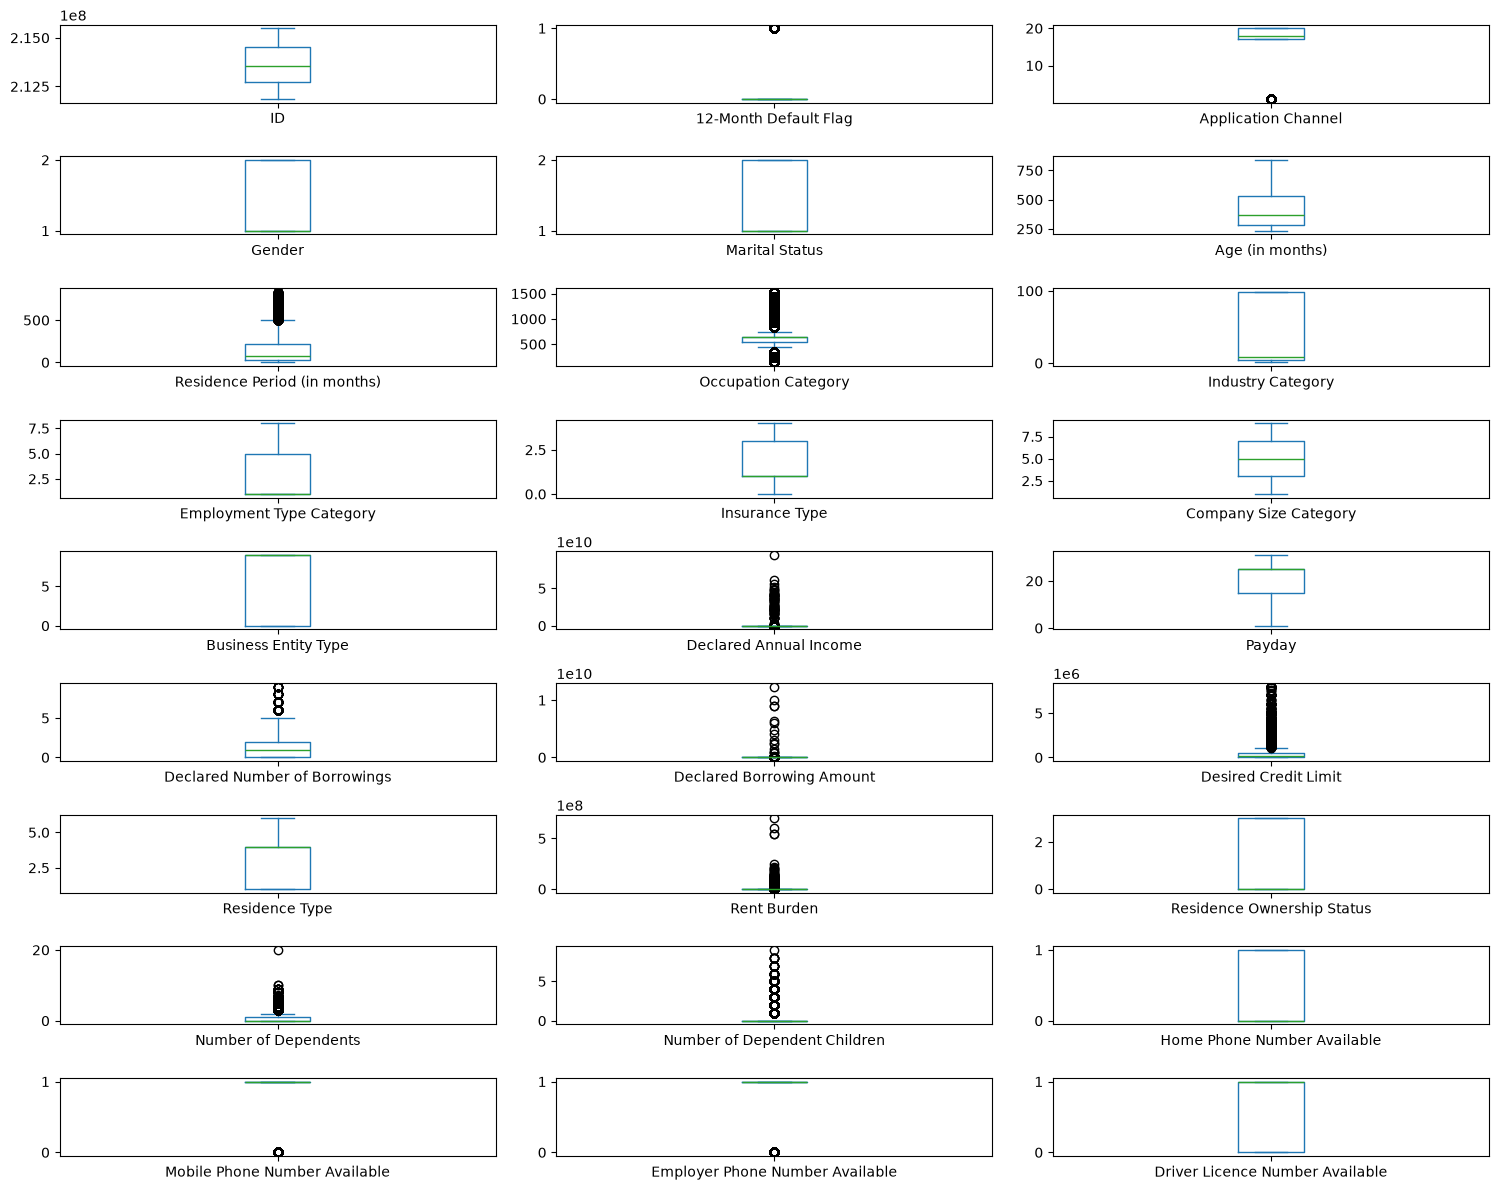

In [86]:
Factors_train_data.select_dtypes(include='number').plot(
    kind='box',
    subplots=True,
    layout=(-1, 3),
    figsize=(15, 12),
    sharex=False,
    sharey=False
)

plt.tight_layout()
plt.show()

#### Class Imbalance


In [87]:
target = '12-Month Default Flag'

# Count
print(Factors_train_data[target].value_counts())

# Percentage
print(Factors_train_data[target].value_counts(normalize=True) * 100)

12-Month Default Flag
0    61913
1     6633
Name: count, dtype: int64
12-Month Default Flag
0    90.323287
1     9.676713
Name: proportion, dtype: float64


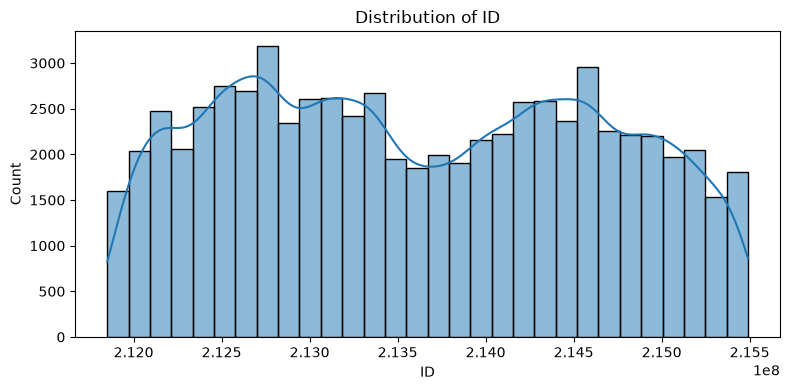

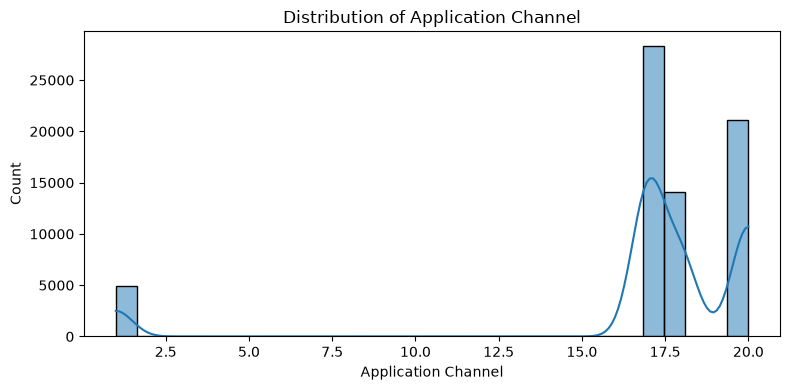

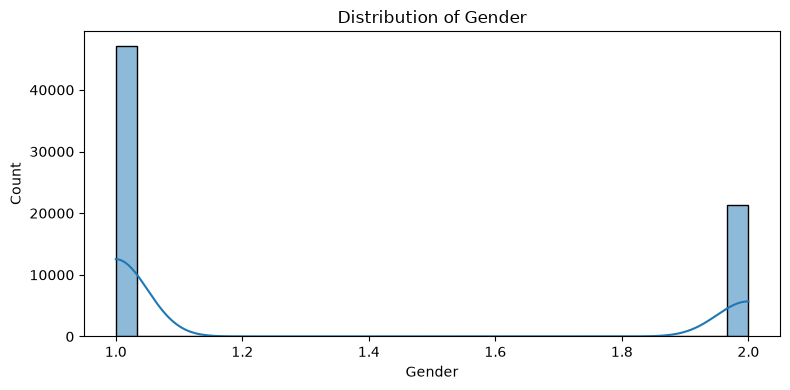

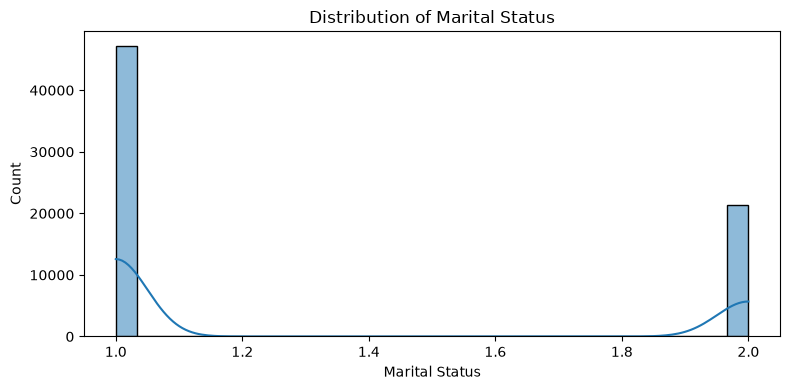

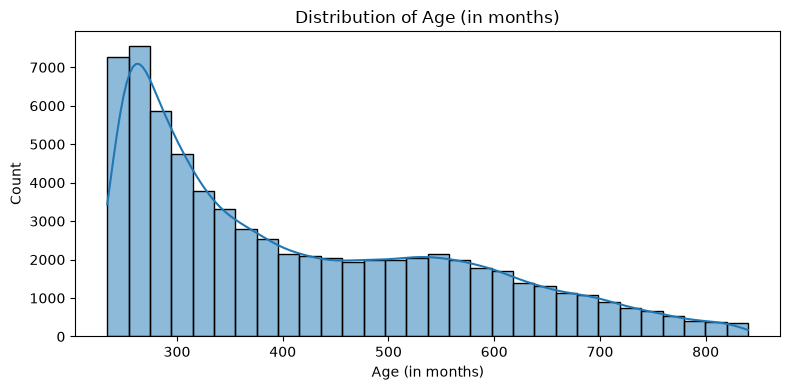

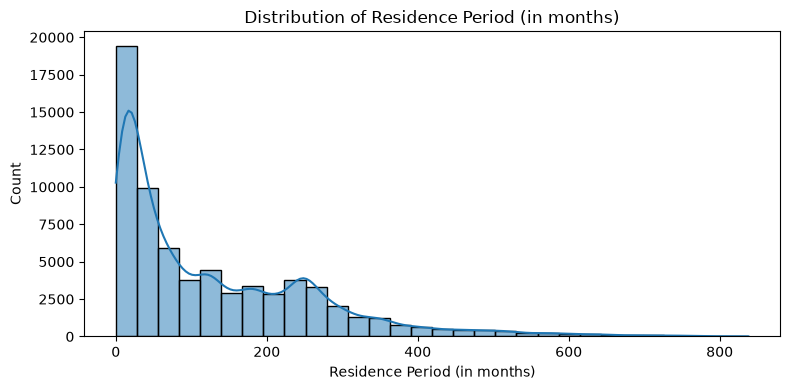

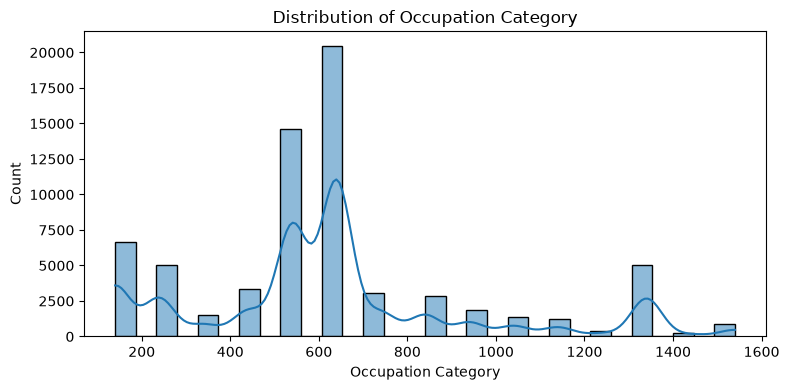

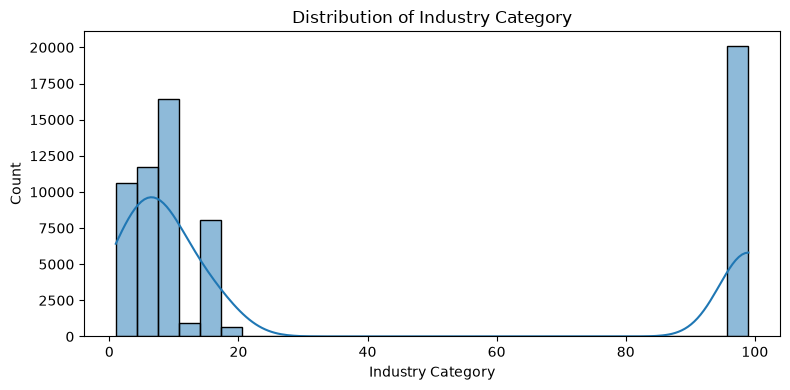

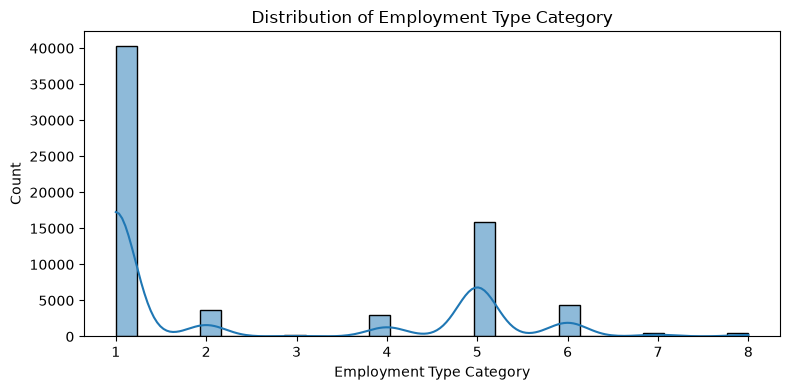

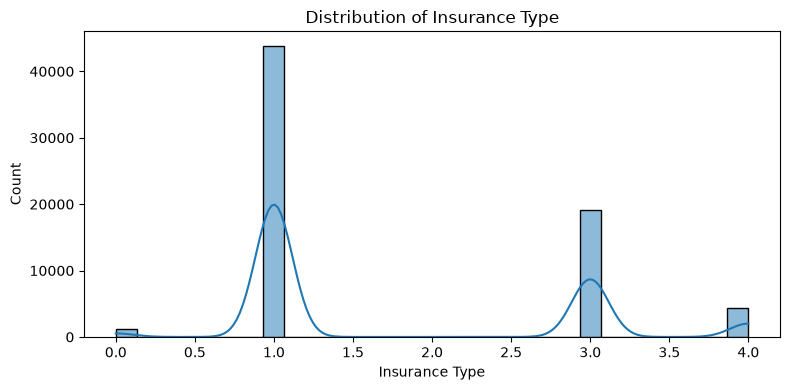

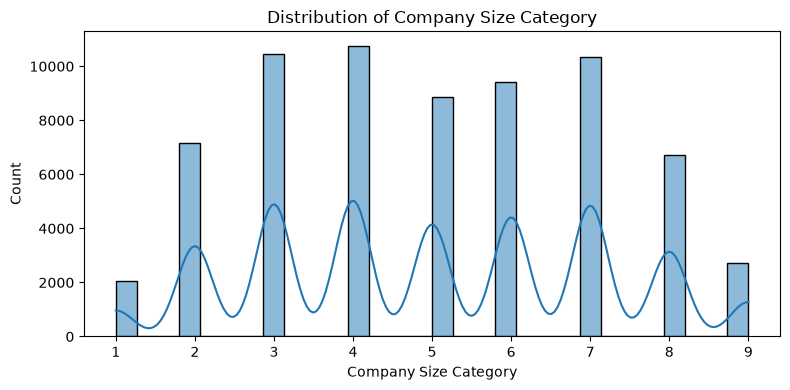

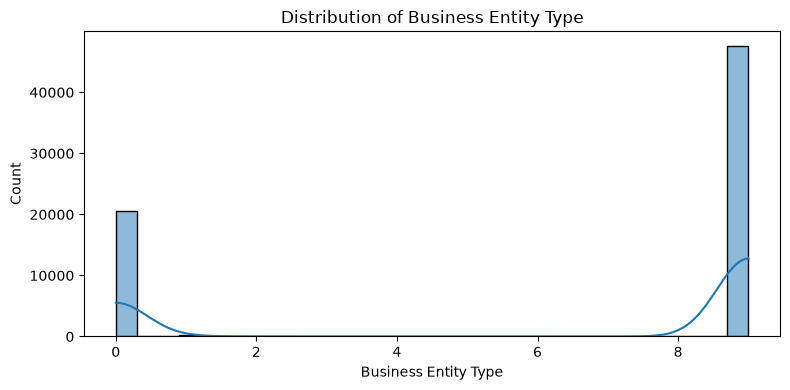

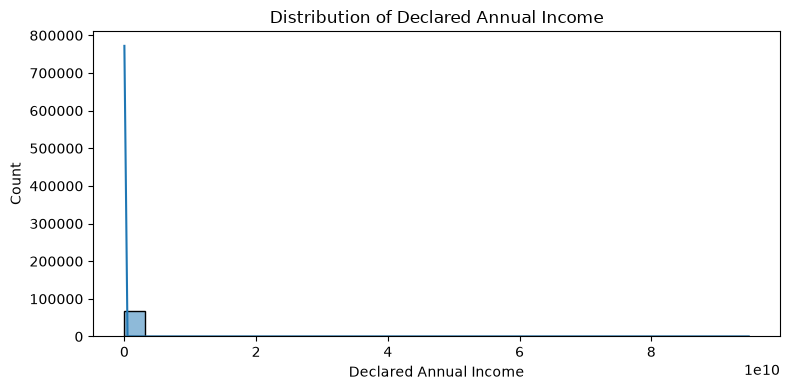

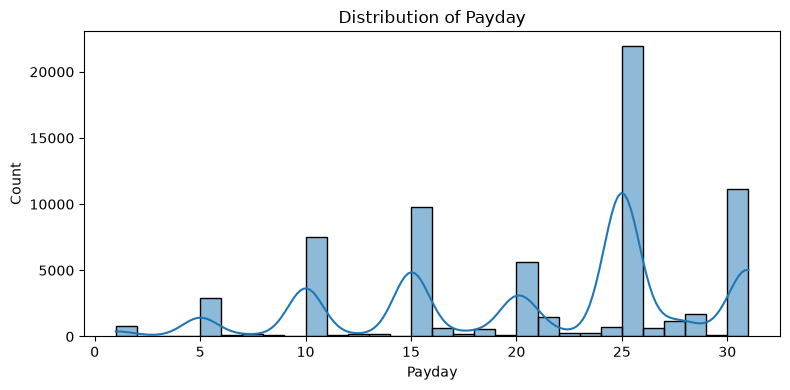

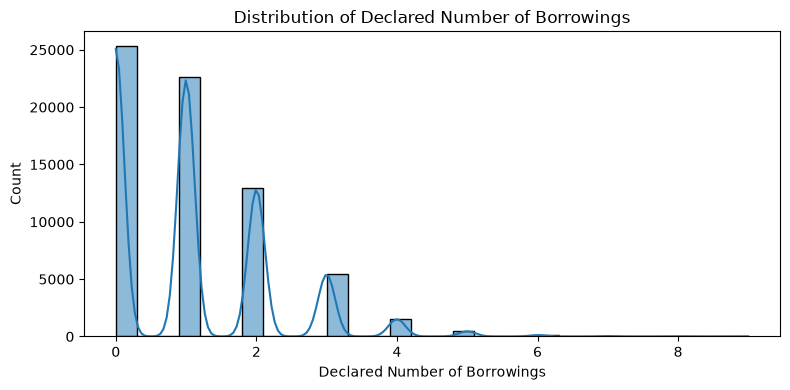

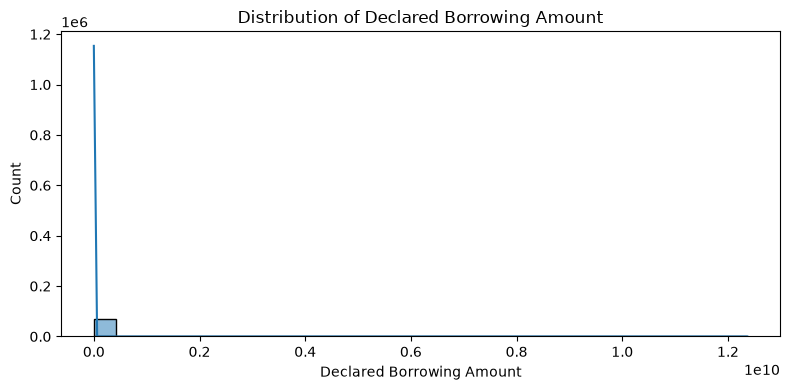

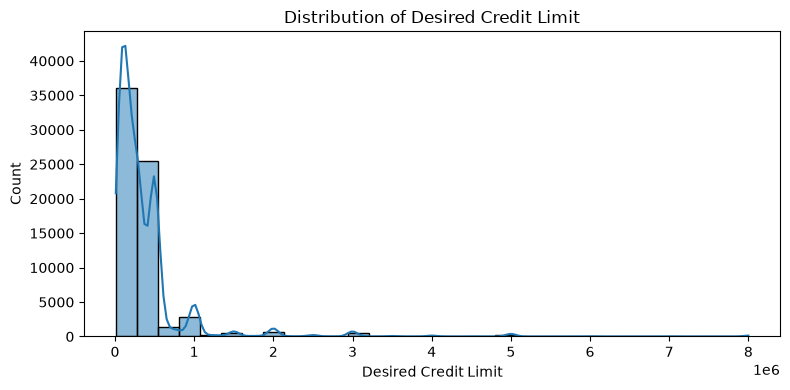

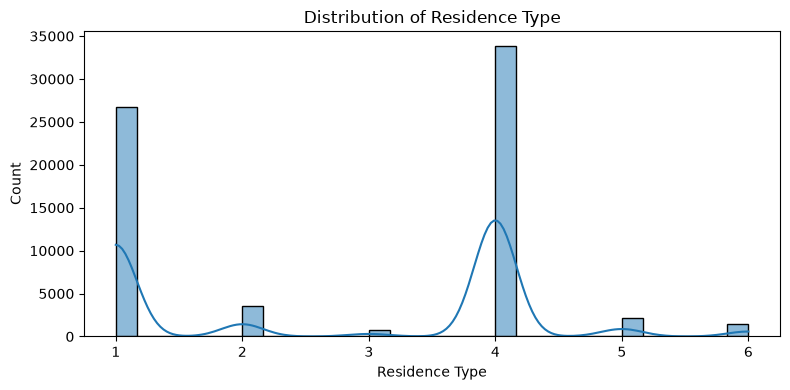

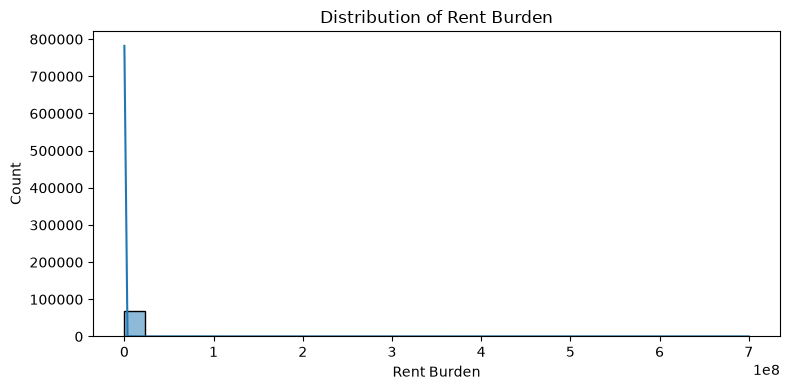

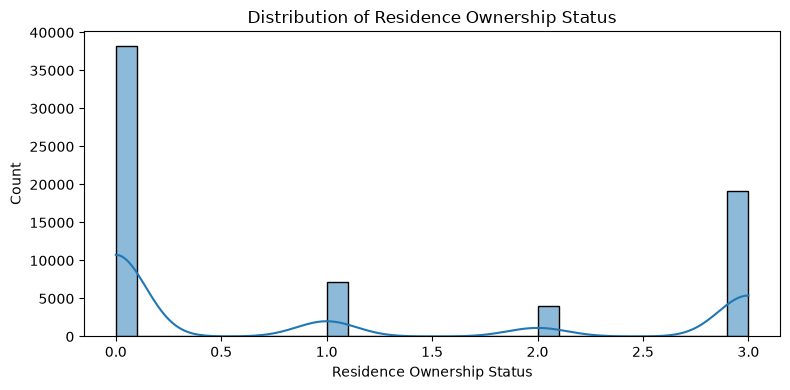

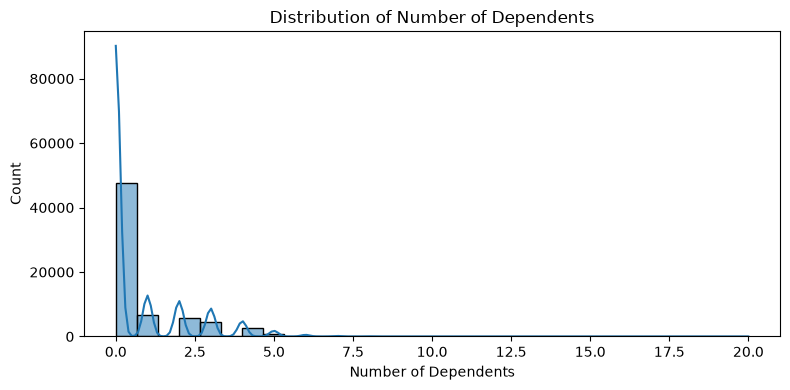

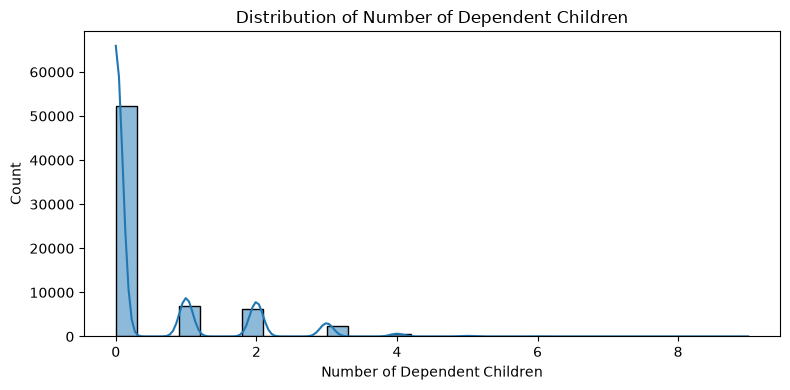

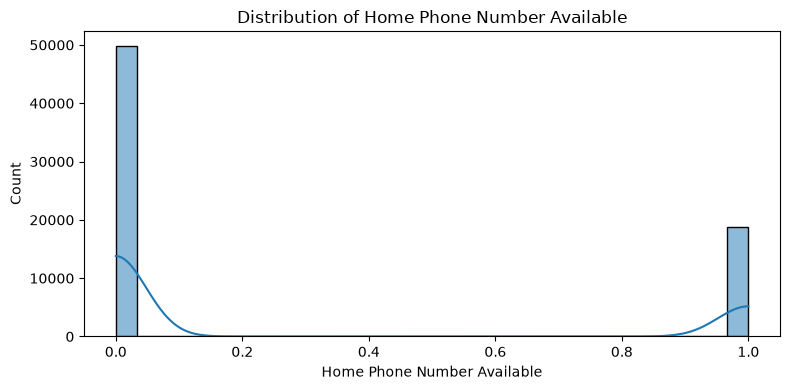

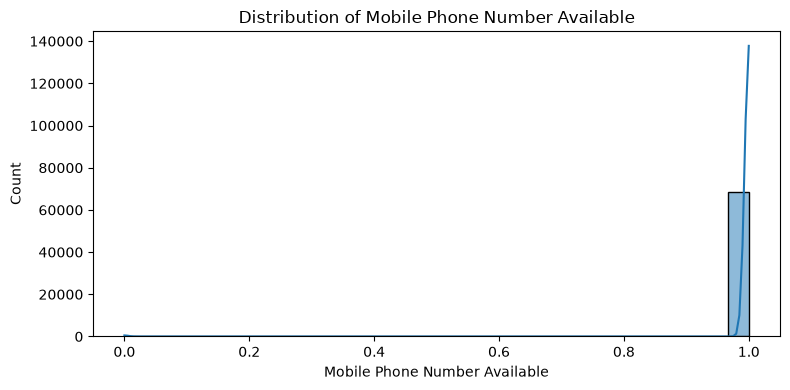

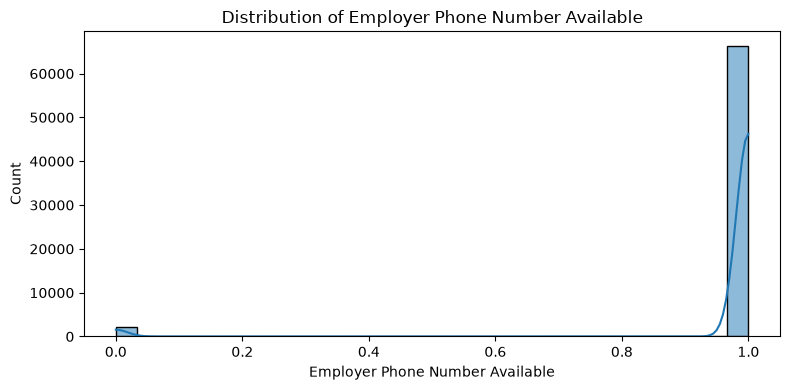

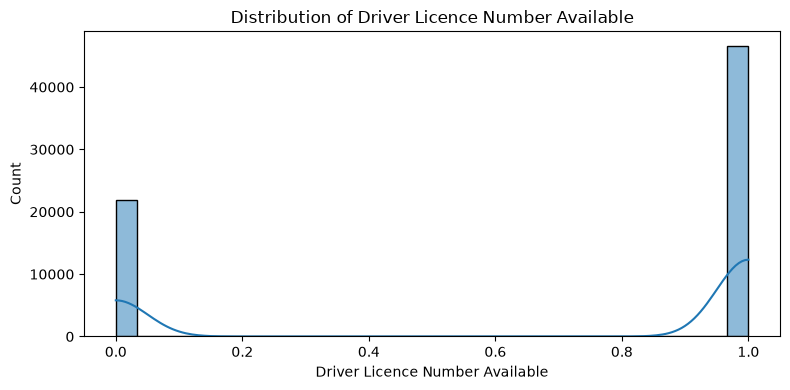

In [88]:
numeric_cols = Factors_train_data.select_dtypes(
    include='number'
).columns.drop(target, errors='ignore')

for col in numeric_cols:
    plt.figure(figsize=(8, 4))

    sns.histplot(
        data=Factors_train_data,
        x=col,
        kde=True,
        bins=30
    )

    plt.title(f"Distribution of {col}")
    plt.tight_layout()
    plt.show()

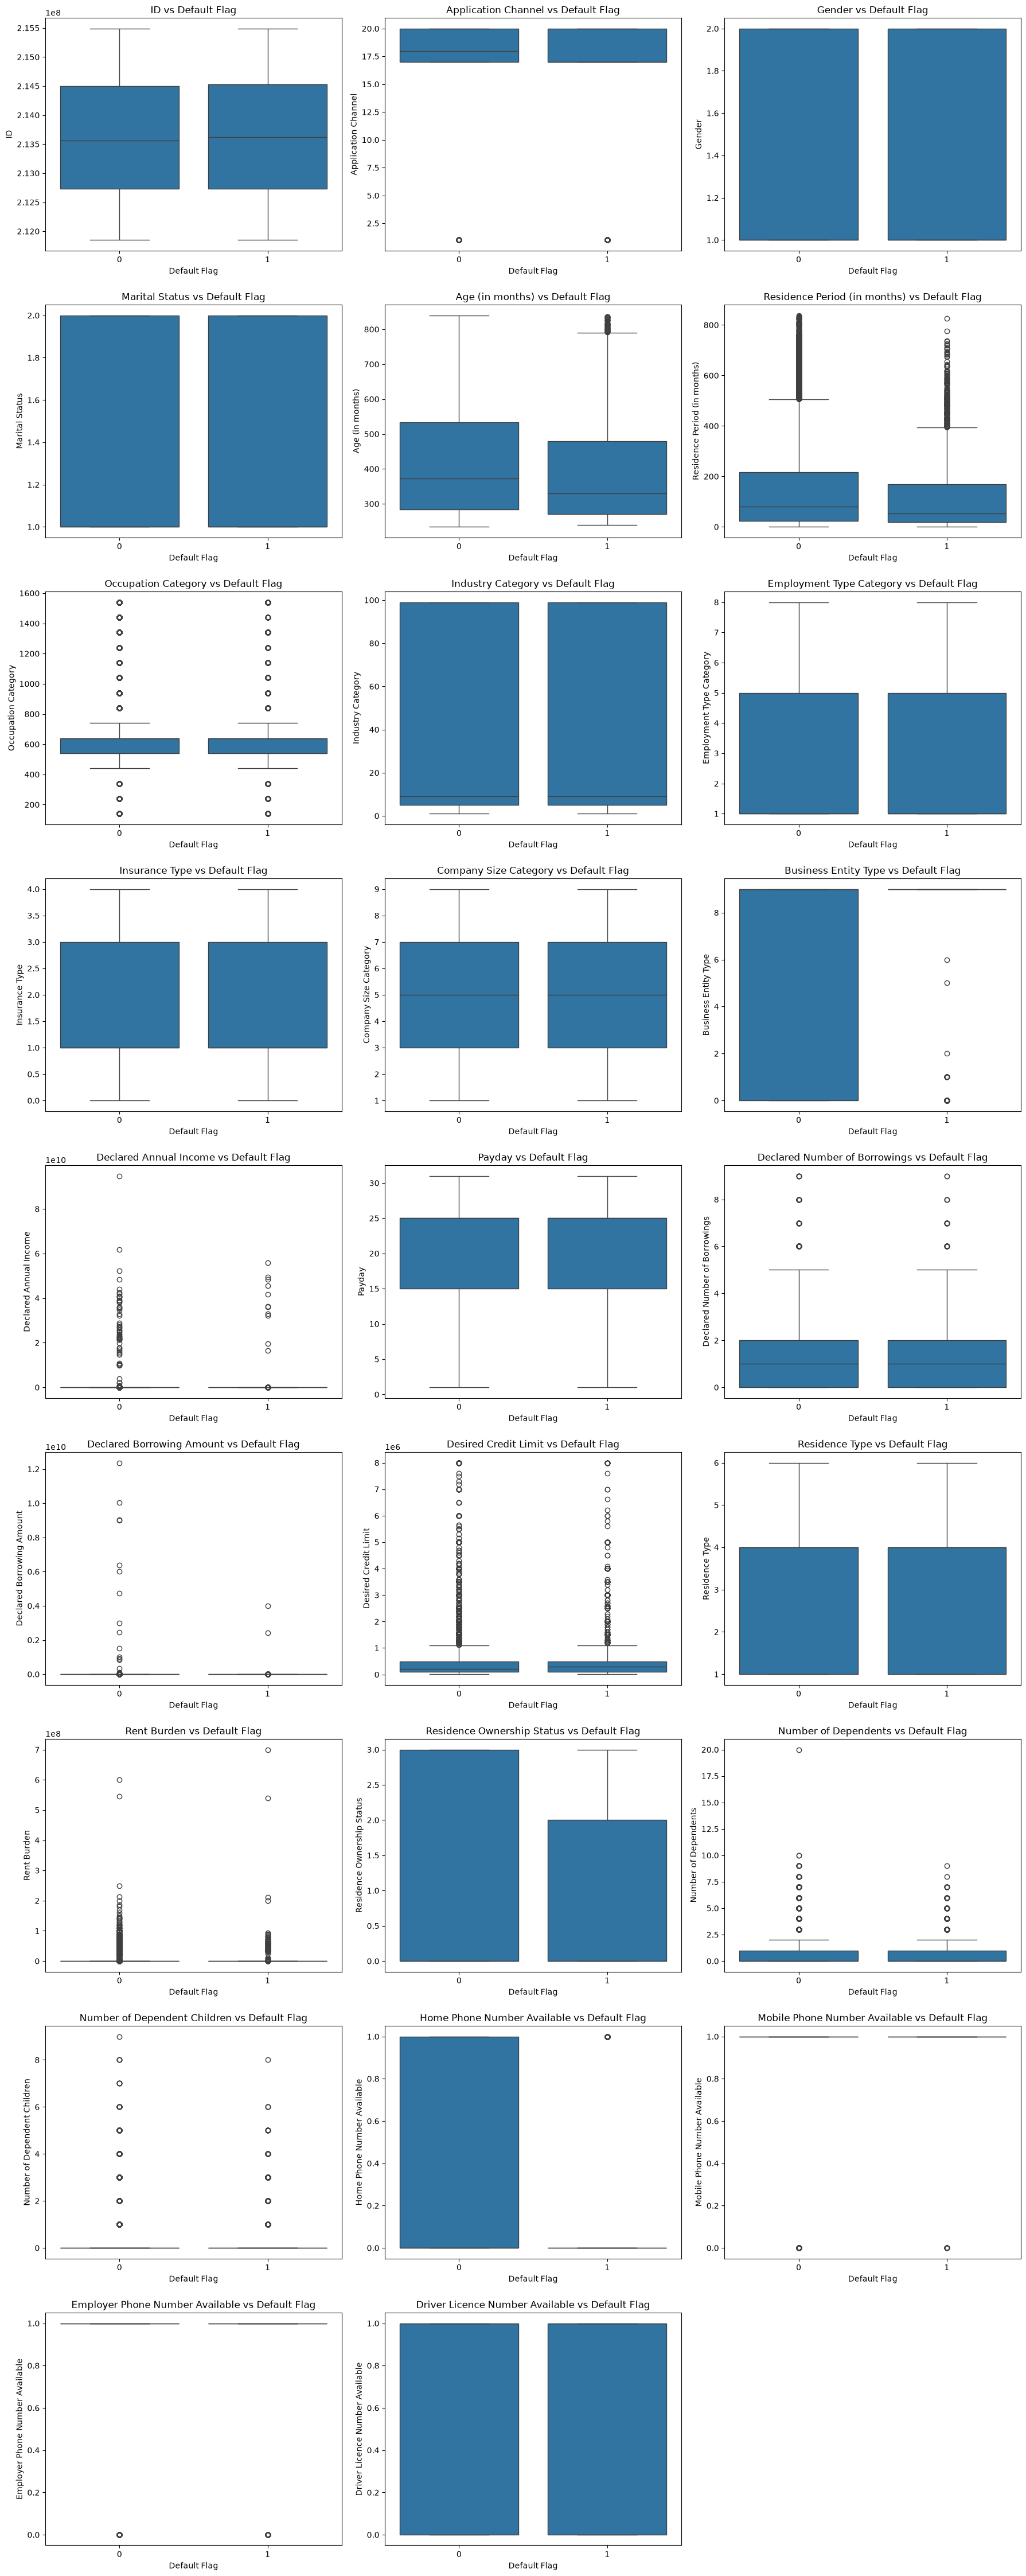

In [89]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

n_cols = 3
n_rows = math.ceil(len(numeric_cols) / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(18, 5 * n_rows)
)

axes = axes.flatten()

for i, col in enumerate(numeric_cols):

    sns.boxplot(
        data=Factors_train_data,
        x=target,
        y=col,
        ax=axes[i]
    )

    axes[i].set_title(f"{col} vs Default Flag")
    axes[i].set_xlabel("Default Flag")
    axes[i].set_ylabel(col)

# ลบช่องว่างที่ไม่มีกราฟ
for j in range(len(numeric_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

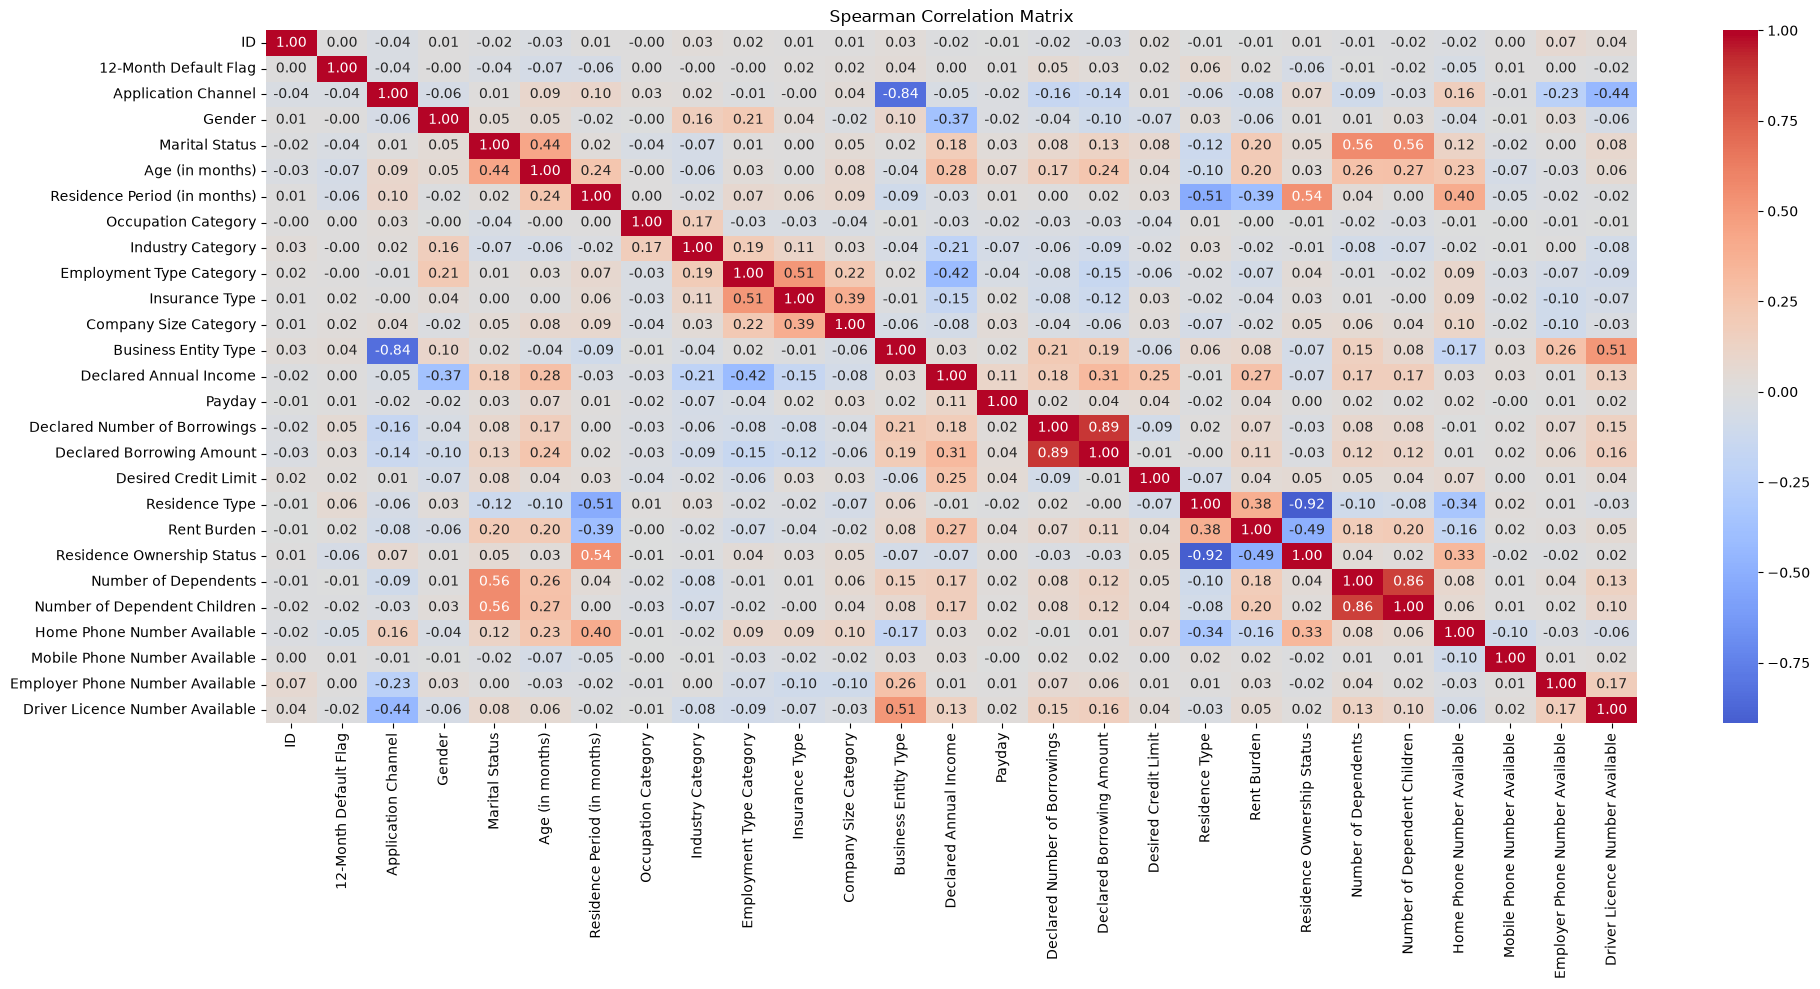

In [90]:
corr = Factors_train_data.select_dtypes(
    include='number'
).corr(method='spearman')

plt.figure(figsize=(20, 10))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    center=0,
    fmt='.2f'
)

plt.title("Spearman Correlation Matrix")
plt.tight_layout()
plt.show()

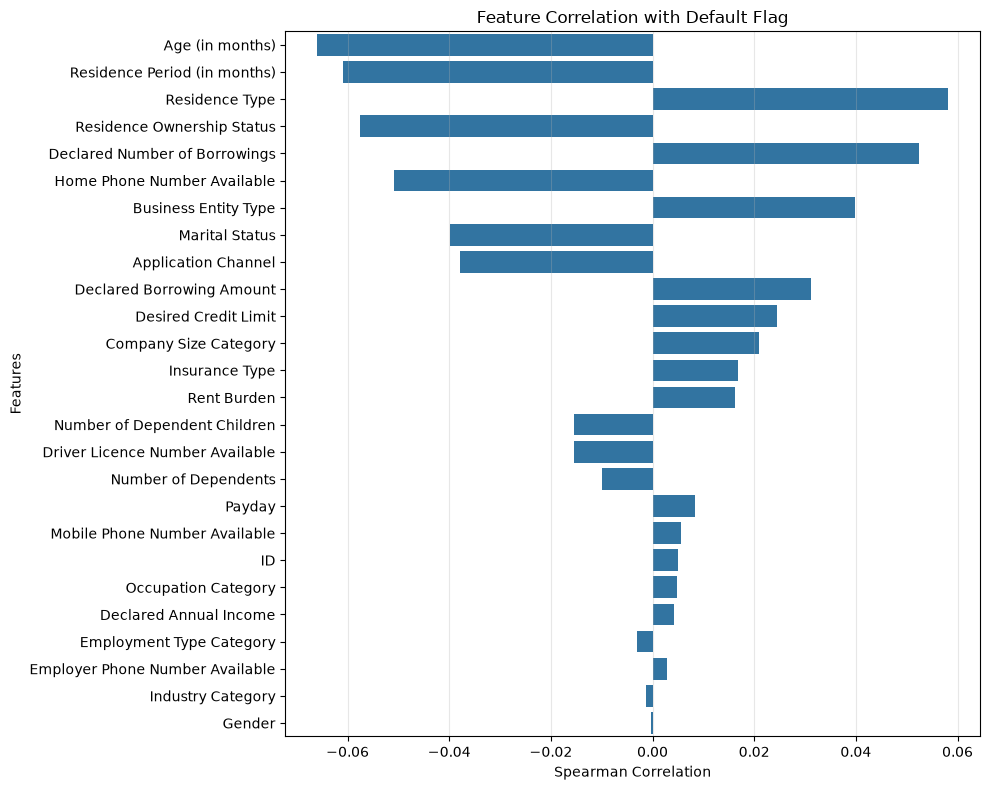

In [91]:
target_corr = (
    corr[target]
    .drop(target)
    .sort_values(key=abs, ascending=False)
)

plt.figure(figsize=(10, 8))

sns.barplot(
    x=target_corr.values,
    y=target_corr.index
)

plt.title("Feature Correlation with Default Flag")
plt.xlabel("Spearman Correlation")
plt.ylabel("Features")
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

In [92]:
train_data[["Declared Annual Income"]].describe()

,Declared Annual Income
count,6.854600e+04
mean,3.186943e+07
std,1.036092e+09
min,0.000000e+00
25%,2.200000e+06
50%,3.000000e+06
75%,4.000000e+06
max,9.480000e+10


#### Analysis target of variable one

In [93]:
one_variable = Factors_train_data[Factors_train_data['12-Month Default Flag'] == 1]
zero_variable = Factors_train_data[Factors_train_data['12-Month Default Flag'] == 0]
one_variable[["Declared Annual Income"]].describe()

,Declared Annual Income
count,6.633000e+03
mean,6.587499e+07
std,1.604557e+09
min,2.000000e+04
25%,2.400000e+06
50%,3.000000e+06
75%,4.000000e+06
max,5.575782e+10


In [94]:
one_variable[["Declared Number of Borrowings"]].describe()

,Declared Number of Borrowings
count,6633.000000
mean,1.293080
std,1.255642
min,0.000000
25%,0.000000
50%,1.000000
75%,2.000000
max,9.000000


In [95]:
one_variable[["Insurance Type"]].describe()

,Insurance Type
count,6633.000000
mean,1.788331
std,1.090922
min,0.000000
25%,1.000000
50%,1.000000
75%,3.000000
max,4.000000


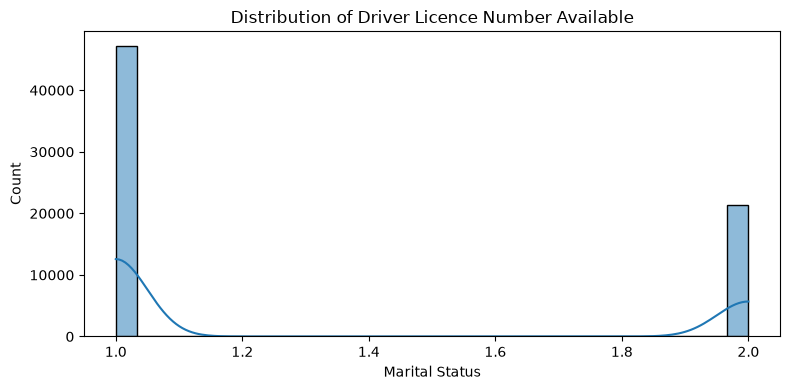

In [96]:
plt.figure(figsize=(8, 4))
sns.histplot(
    data=Factors_train_data,
    x="Marital Status",
    kde=True,
    bins=30
)

plt.title(f"Distribution of {col}")
plt.tight_layout()
plt.show()

In [97]:
print(len(zero_variable))
zero_variable[["Business Entity Type"]].describe()

61913


,Business Entity Type
count,61913.000000
mean,6.205514
std,4.158335
min,0.000000
25%,0.000000
50%,9.000000
75%,9.000000
max,9.000000


In [98]:
zero_variable[["Insurance Type"]].describe()

,Insurance Type
count,61913.000000
mean,1.728151
std,1.082937
min,0.000000
25%,1.000000
50%,1.000000
75%,3.000000
max,4.000000


In [99]:
Male = train_data[train_data['Gender'] == 1]
Famale = train_data[train_data['Gender'] == 2]

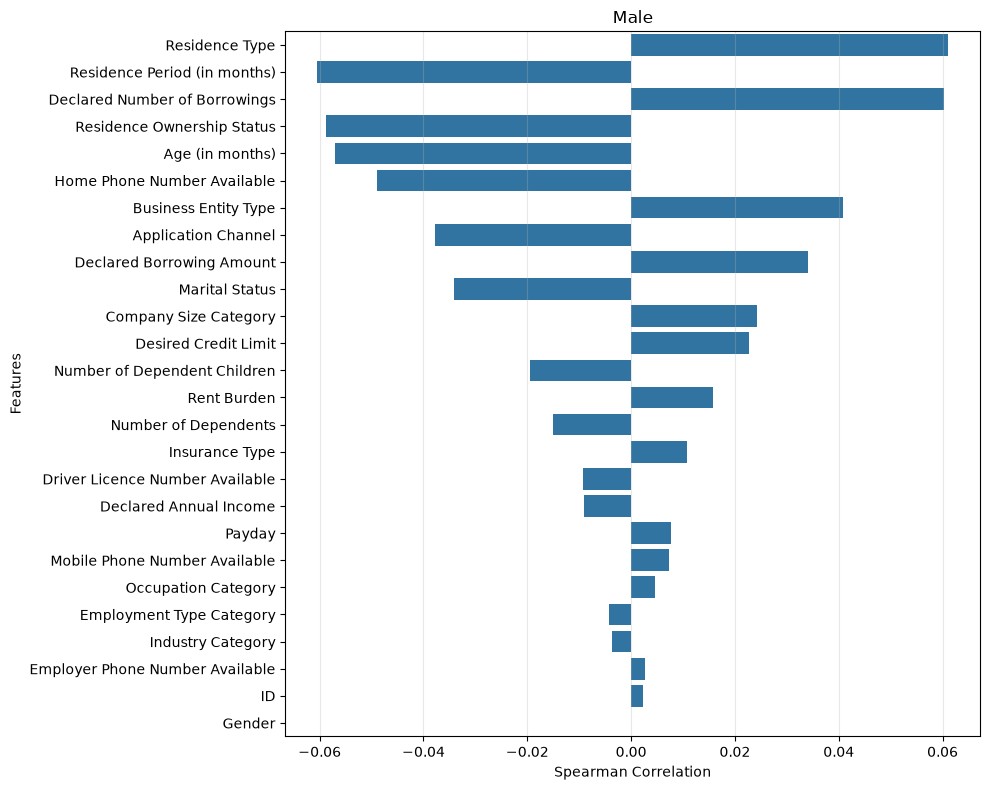

In [100]:
Male_corr = Male.select_dtypes(
    include='number'
).corr(method='spearman')

target_corr = (
    Male_corr[target]
    .drop(target)
    .sort_values(key=abs, ascending=False)
)

plt.figure(figsize=(10, 8))

sns.barplot(
    x=target_corr.values,
    y=target_corr.index
)

plt.title("Male")
plt.xlabel("Spearman Correlation")
plt.ylabel("Features")
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

In [101]:
Famale[['12-Month Default Flag']].value_counts()

12-Month Default Flag
0                        19339
1                         2069
Name: count, dtype: int64

In [102]:
Male[['12-Month Default Flag']].value_counts()

12-Month Default Flag
0                        42574
1                         4564
Name: count, dtype: int64

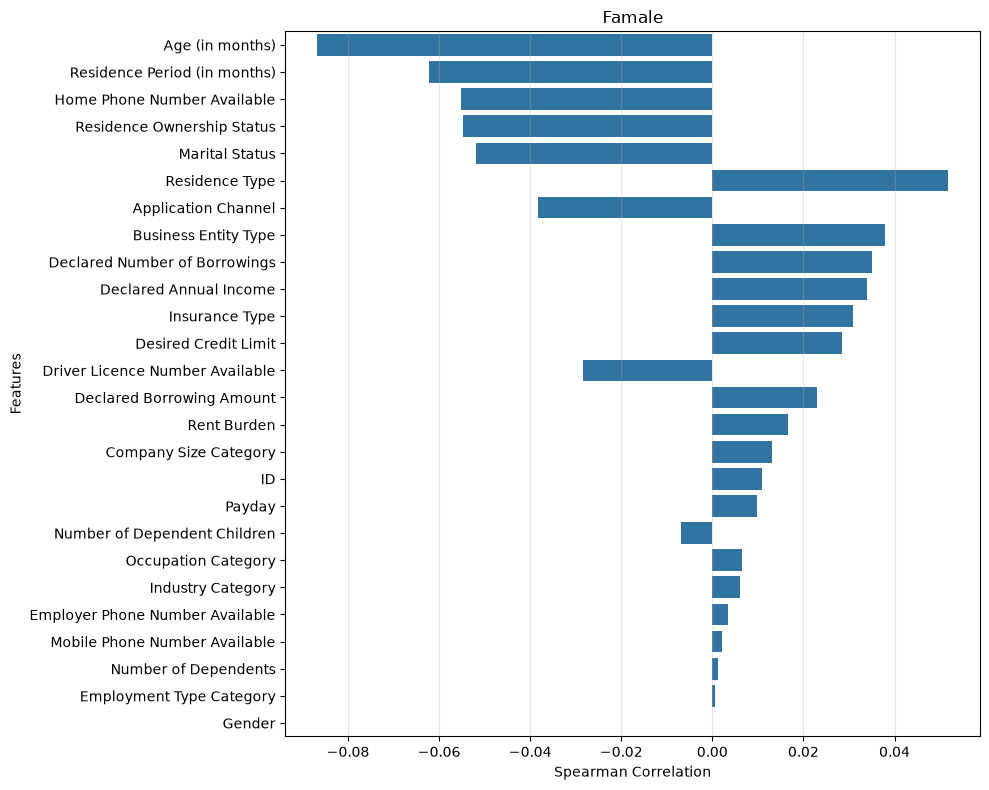

In [103]:
Famale_corr = Famale.select_dtypes(
    include='number'
).corr(method='spearman')

target_corr = (
    Famale_corr[target]
    .drop(target)
    .sort_values(key=abs, ascending=False)
)

plt.figure(figsize=(10, 8))

sns.barplot(
    x=target_corr.values,
    y=target_corr.index
)

plt.title("Famale")
plt.xlabel("Spearman Correlation")
plt.ylabel("Features")
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

In [104]:
print(len(one_variable))
one_variable.describe()

6633


,ID,12-Month Default Flag,Application Channel,Gender,Marital Status,Age (in months),Residence Period (in months),Occupation Category,Industry Category,Employment Type Category,...,Desired Credit Limit,Residence Type,Rent Burden,Residence Ownership Status,Number of Dependents,Number of Dependent Children,Home Phone Number Available,Mobile Phone Number Available,Employer Phone Number Available,Driver Licence Number Available
count,6.633000e+03,6633.0,6633.000000,6633.000000,6633.000000,6633.000000,6633.000000,6633.000000,6633.000000,6633.000000,...,6.633000e+03,6633.000000,6.633000e+03,6633.000000,6633.000000,6633.000000,6633.000000,6633.000000,6633.000000,6633.000000
mean,2.136403e+08,1.0,16.990653,1.311925,1.255088,385.749284,106.602442,639.879391,35.159053,2.485150,...,4.189145e+05,3.069652,7.985363e+05,0.851651,0.683853,0.381728,0.203679,0.997286,0.969245,0.657923
std,1.026759e+06,0.0,4.226036,0.463314,0.435944,142.514186,121.054152,328.216638,42.388563,1.962894,...,7.049199e+05,1.480667,1.265205e+07,1.260422,1.275999,0.832420,0.402763,0.052026,0.172667,0.474441
min,2.118500e+08,1.0,1.000000,1.000000,1.000000,240.000000,0.000000,140.000000,1.000000,1.000000,...,1.000000e+04,1.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.127308e+08,1.0,17.000000,1.000000,1.000000,271.000000,18.000000,540.000000,5.000000,1.000000,...,1.000000e+05,1.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000
50%,2.136204e+08,1.0,17.000000,1.000000,1.000000,330.000000,54.000000,640.000000,9.000000,1.000000,...,3.000000e+05,4.000000,2.100000e+04,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000
75%,2.145301e+08,1.0,20.000000,2.000000,2.000000,479.000000,169.000000,640.000000,99.000000,5.000000,...,5.000000e+05,4.000000,5.400000e+04,2.000000,1.000000,0.000000,0.000000,1.000000,1.000000,1.000000
max,2.154902e+08,1.0,20.000000,2.000000,2.000000,837.000000,827.000000,1540.000000,99.000000,8.000000,...,8.000000e+06,6.000000,7.000000e+08,3.000000,9.000000,8.000000,1.000000,1.000000,1.000000,1.000000


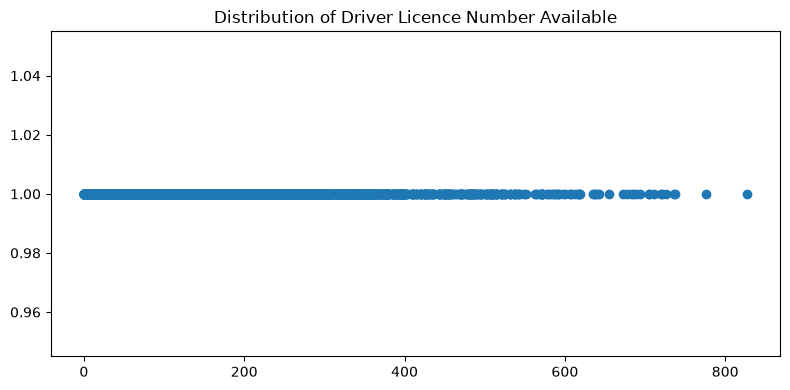

In [105]:
plt.figure(figsize=(8, 4))
plt.scatter(one_variable[["Residence Period (in months)"]],one_variable[['12-Month Default Flag']])

plt.title(f"Distribution of {col}")
plt.tight_layout()
plt.show()

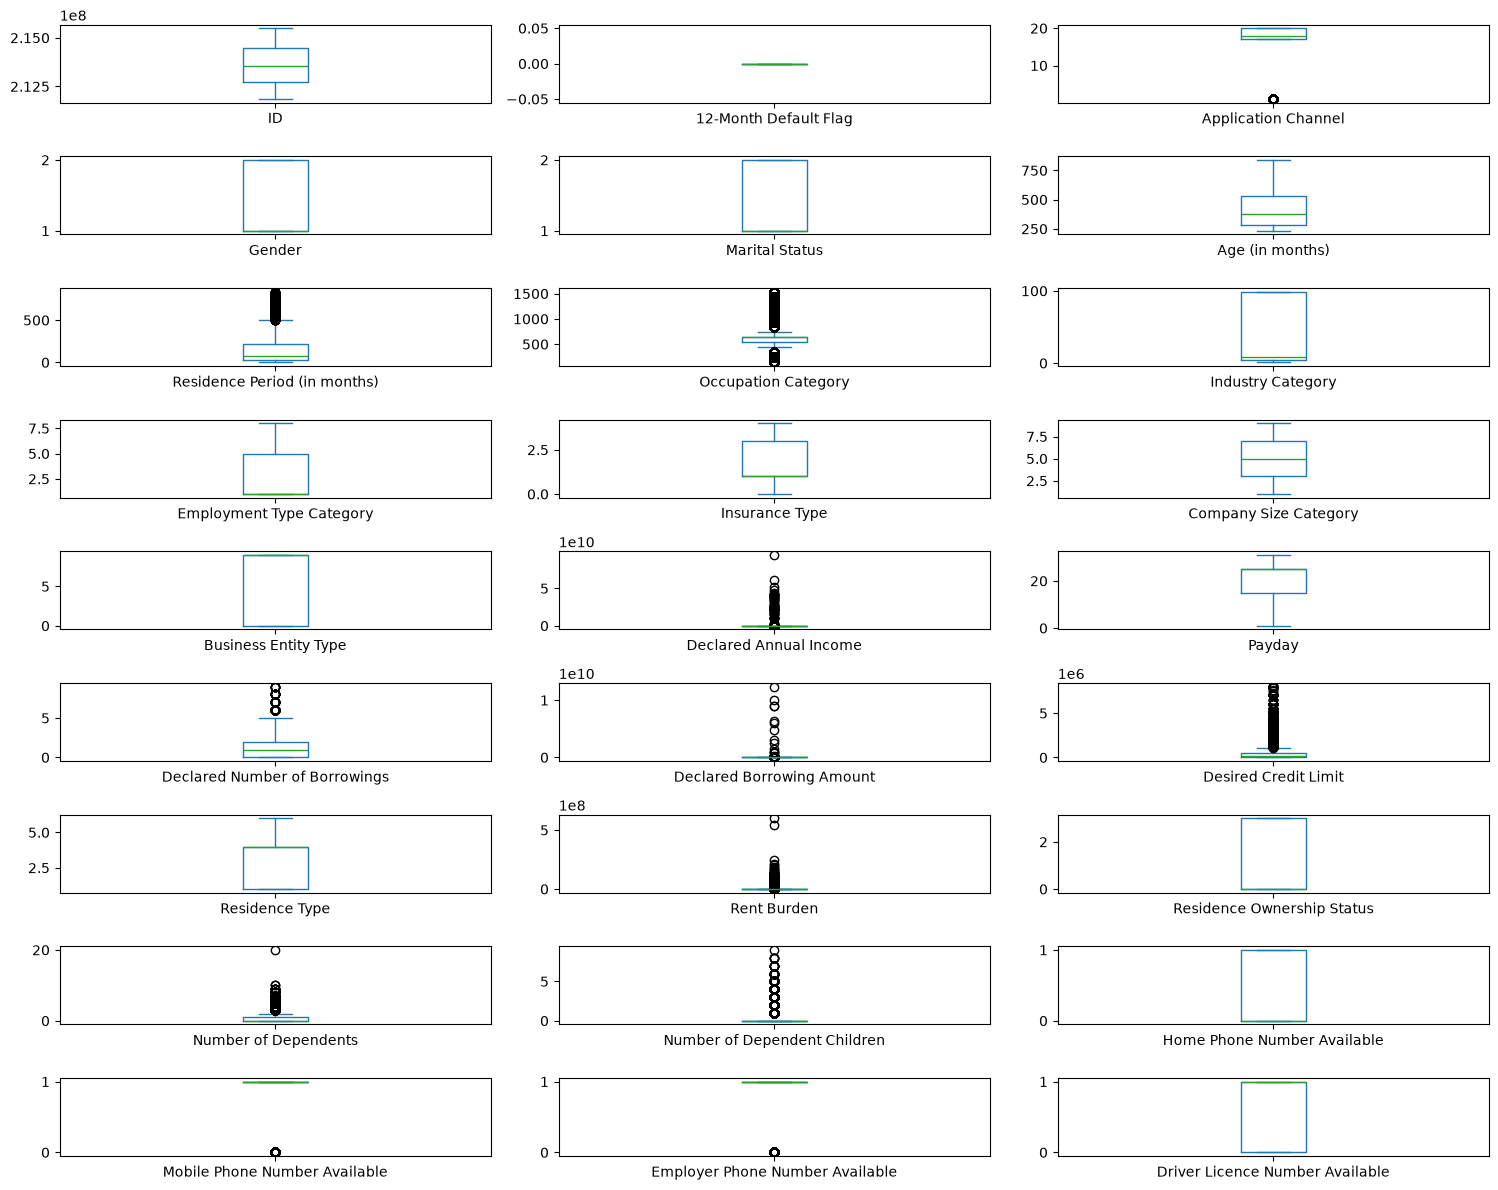

In [106]:
zero_variable.select_dtypes(include='number').plot(
    kind='box',
    subplots=True,
    layout=(-1, 3),
    figsize=(15, 12),
    sharex=False,
    sharey=False
)

plt.tight_layout()
plt.show()

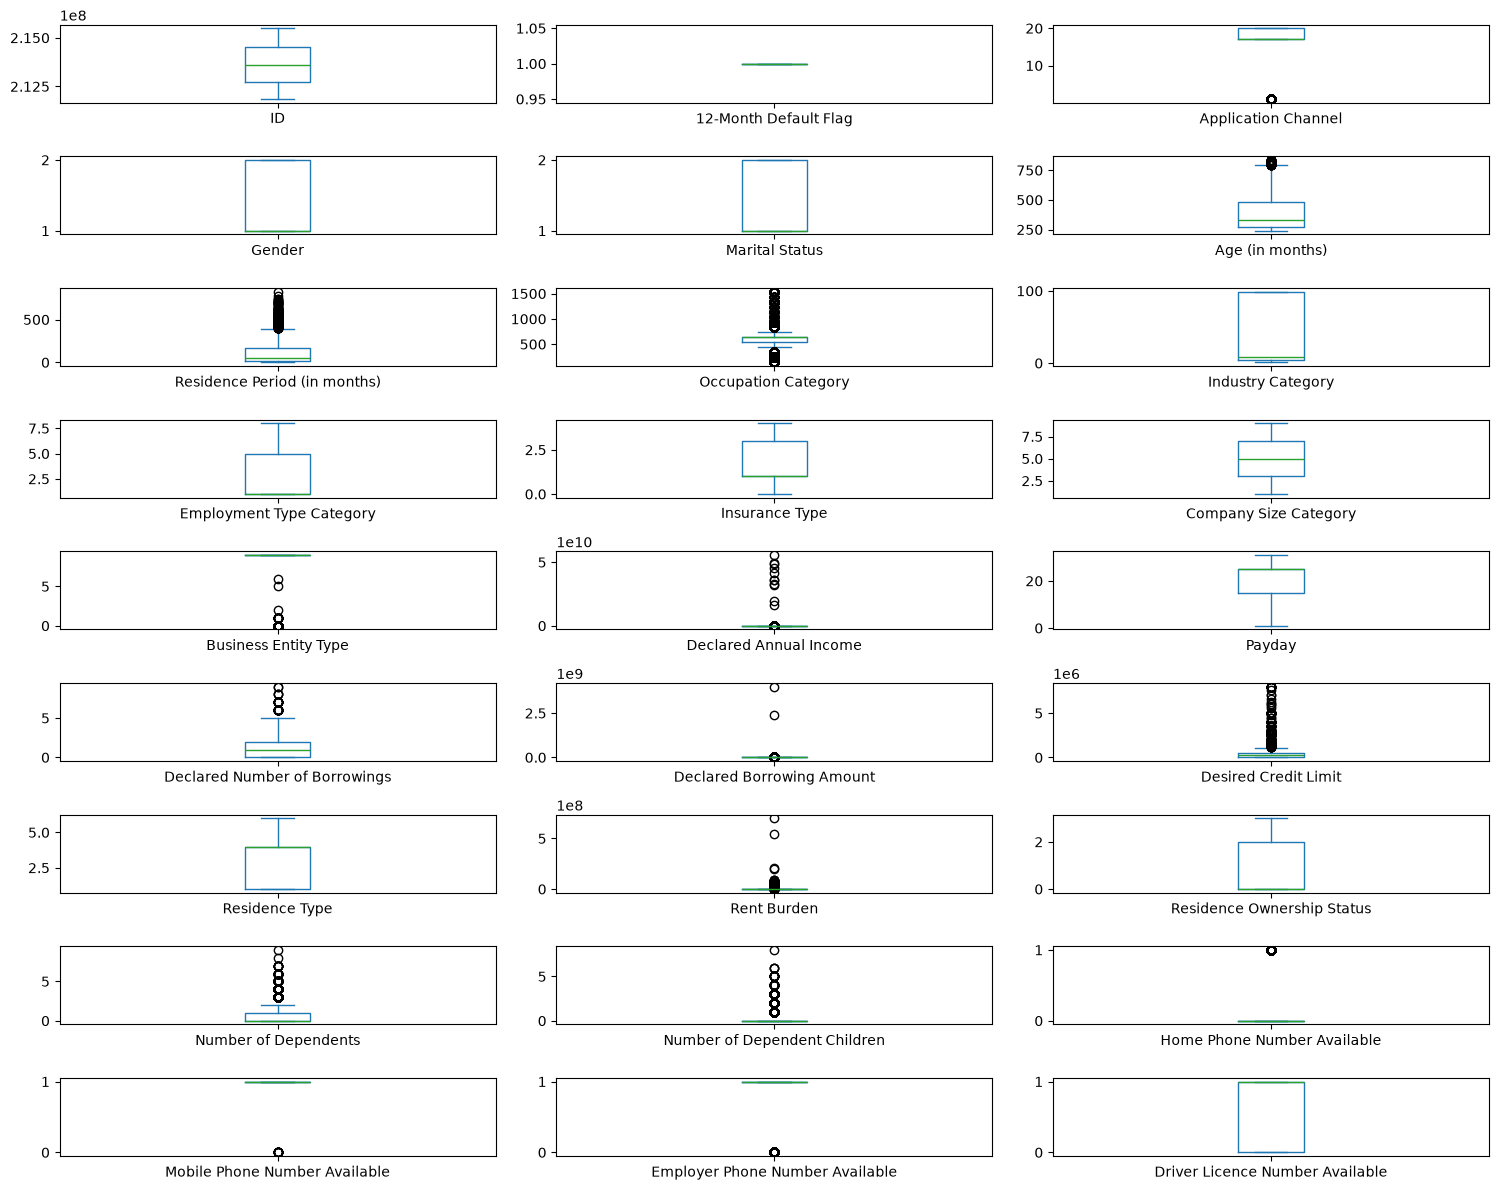

In [107]:
one_variable.select_dtypes(include='number').plot(
    kind='box',
    subplots=True,
    layout=(-1, 3),
    figsize=(15, 12),
    sharex=False,
    sharey=False
)

plt.tight_layout()
plt.show()

##

In [108]:
df = train_data.copy()

In [109]:
for col in [
    'Gender',
    'Insurance Type',
    'Business Entity Type',
    'Company Size Category'
]:
    freq = train_data[col].value_counts(normalize=True)
    train_data[f'{col}_Frequency'] = train_data[col].map(freq)

In [110]:
train_data

,ID,12-Month Default Flag,Application Channel,Gender,Marital Status,Age (in months),Residence Period (in months),Occupation Category,Industry Category,Employment Type Category,...,Number of Dependents,Number of Dependent Children,Home Phone Number Available,Mobile Phone Number Available,Employer Phone Number Available,Driver Licence Number Available,Gender_Frequency,Insurance Type_Frequency,Business Entity Type_Frequency,Company Size Category_Frequency
0,211880002,0,18,1,2,699,141,140,8,6,...,2,1,1,1,1,1,0.687684,0.064657,0.694585,0.097934
1,211870004,0,20,2,2,419,26,640,1,1,...,1,0,0,1,0,0,0.312316,0.278587,0.300514,0.152744
2,211930001,0,1,2,1,322,181,540,8,5,...,0,0,0,1,1,1,0.312316,0.639585,0.694585,0.137616
3,211920001,0,17,1,1,328,328,640,1,5,...,0,0,1,1,1,1,0.687684,0.278587,0.694585,0.129388
4,211880003,1,18,1,1,451,44,1040,16,1,...,0,0,0,1,1,1,0.687684,0.639585,0.694585,0.129388
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
68541,215470332,0,17,1,2,372,372,640,99,5,...,1,0,0,1,1,1,0.687684,0.278587,0.694585,0.137616
68542,215470333,0,18,2,1,362,18,640,99,5,...,1,1,0,1,1,0,0.312316,0.278587,0.694585,0.137616
68543,215480285,0,18,1,2,457,44,340,4,1,...,2,1,0,1,1,1,0.687684,0.639585,0.694585,0.151139
68544,215470336,0,20,1,1,293,293,640,9,4,...,0,0,1,1,0,0,0.687684,0.639585,0.300514,0.129388


In [111]:
business_analysis = (
    df.groupby('Number of Dependent Children')
      .agg(
          Total_Count=('12-Month Default Flag', 'size'),
          Default_Count=('12-Month Default Flag', 'sum'),
          Default_Rate=('12-Month Default Flag', 'mean')
      )
      .sort_values('Default_Rate', ascending=False)
)

business_analysis['Default_Rate'] *= 100

business_analysis

,Total_Count,Default_Count,Default_Rate
Number of Dependent Children,,,
8,5,1,20.000000
5,113,15,13.274336
6,26,3,11.538462
0,52357,5183,9.899345
1,6925,685,9.891697
2,6218,530,8.523641
4,498,38,7.630522
3,2396,178,7.429048
7,7,0,0.000000


In [112]:
company_analysis = (
    df.groupby('Company Size Category')['12-Month Default Flag']
      .agg(
          Total_Count='count',
          Default_Count='sum',
          Default_Rate='mean'
      )
      .sort_values('Default_Rate', ascending=False)
)

company_analysis['Default_Rate'] *= 100

company_analysis

,Total_Count,Default_Count,Default_Rate
Company Size Category,,,
7,10360,1179,11.380309
6,9433,981,10.399661
4,10756,1096,10.189662
3,10470,990,9.455587
5,8869,823,9.279513
8,6713,619,9.220915
9,2730,244,8.937729
2,7155,576,8.050314
1,2060,125,6.067961


##

In [113]:
from scipy.stats import chi2_contingency
import numpy as np

contingency_table = pd.crosstab(
    df['Number of Dependent Children'],
    df['12-Month Default Flag']
)

chi2, p_value, dof, expected = chi2_contingency(contingency_table)

n = contingency_table.to_numpy().sum()
r, k = contingency_table.shape

cramers_v = np.sqrt(
    chi2 / (n * min(r - 1, k - 1))
)

print(f"Chi-square p-value: {p_value:.6f}")
print(f"Cramér's V: {cramers_v:.4f}")

Chi-square p-value: 0.000179
Cramér's V: 0.0217


In [114]:
col = 'Number of Dependent Children'

df['Dependent_Squared'] = df[col] ** 2
df['Dependent_Log'] = np.log1p(df[col])

In [115]:
df

,ID,12-Month Default Flag,Application Channel,Gender,Marital Status,Age (in months),Residence Period (in months),Occupation Category,Industry Category,Employment Type Category,...,Rent Burden,Residence Ownership Status,Number of Dependents,Number of Dependent Children,Home Phone Number Available,Mobile Phone Number Available,Employer Phone Number Available,Driver Licence Number Available,Dependent_Squared,Dependent_Log
0,211880002,0,18,1,2,699,141,140,8,6,...,50000,1,2,1,1,1,1,1,1,0.693147
1,211870004,0,20,2,2,419,26,640,1,1,...,0,0,1,0,0,1,0,0,0,0.000000
2,211930001,0,1,2,1,322,181,540,8,5,...,0,3,0,0,0,1,1,1,0,0.000000
3,211920001,0,17,1,1,328,328,640,1,5,...,0,3,0,0,1,1,1,1,0,0.000000
4,211880003,1,18,1,1,451,44,1040,16,1,...,60000,0,0,0,0,1,1,1,0,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
68541,215470332,0,17,1,2,372,372,640,99,5,...,0,2,1,0,0,1,1,1,0,0.000000
68542,215470333,0,18,2,1,362,18,640,99,5,...,53000,0,1,1,0,1,1,0,1,0.693147
68543,215480285,0,18,1,2,457,44,340,4,1,...,0,2,2,1,0,1,1,1,1,0.693147
68544,215470336,0,20,1,1,293,293,640,9,4,...,0,3,0,0,1,1,0,0,0,0.000000


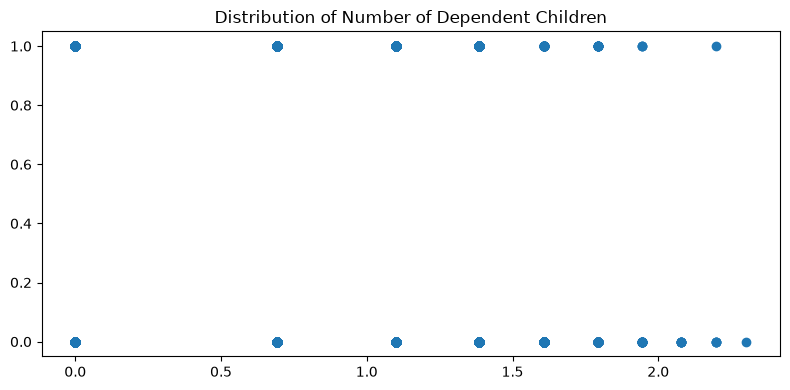

In [116]:
plt.figure(figsize=(8, 4))
plt.scatter(df[["Dependent_Log"]],df[['12-Month Default Flag']])

plt.title(f"Distribution of {col}")
plt.tight_layout()
plt.show()

In [117]:
df['Borrowing_Count_Group'] = pd.cut(
    df['Declared Number of Borrowings'],
    bins=[-1, 0, 1, 3, 5, np.inf],
    labels=[
        'No_Borrowing',
        'One_Borrowing',
        'Few_Borrowings',
        'Multiple_Borrowings',
        'Many_Borrowings'
    ]
)

In [118]:
df

,ID,12-Month Default Flag,Application Channel,Gender,Marital Status,Age (in months),Residence Period (in months),Occupation Category,Industry Category,Employment Type Category,...,Residence Ownership Status,Number of Dependents,Number of Dependent Children,Home Phone Number Available,Mobile Phone Number Available,Employer Phone Number Available,Driver Licence Number Available,Dependent_Squared,Dependent_Log,Borrowing_Count_Group
0,211880002,0,18,1,2,699,141,140,8,6,...,1,2,1,1,1,1,1,1,0.693147,Few_Borrowings
1,211870004,0,20,2,2,419,26,640,1,1,...,0,1,0,0,1,0,0,0,0.000000,Multiple_Borrowings
2,211930001,0,1,2,1,322,181,540,8,5,...,3,0,0,0,1,1,1,0,0.000000,One_Borrowing
3,211920001,0,17,1,1,328,328,640,1,5,...,3,0,0,1,1,1,1,0,0.000000,Few_Borrowings
4,211880003,1,18,1,1,451,44,1040,16,1,...,0,0,0,0,1,1,1,0,0.000000,One_Borrowing
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
68541,215470332,0,17,1,2,372,372,640,99,5,...,2,1,0,0,1,1,1,0,0.000000,One_Borrowing
68542,215470333,0,18,2,1,362,18,640,99,5,...,0,1,1,0,1,1,0,1,0.693147,No_Borrowing
68543,215480285,0,18,1,2,457,44,340,4,1,...,2,2,1,0,1,1,1,1,0.693147,Few_Borrowings
68544,215470336,0,20,1,1,293,293,640,9,4,...,3,0,0,1,1,0,0,0,0.000000,One_Borrowing


In [119]:
train_data.columns

Index(['ID', '12-Month Default Flag', 'Application Channel', 'Gender',
       'Marital Status', 'Age (in months)', 'Residence Period (in months)',
       'Occupation Category', 'Industry Category', 'Employment Type Category',
       'Insurance Type', 'Company Size Category', 'Business Entity Type',
       'Declared Annual Income', 'Payday', 'Declared Number of Borrowings',
       'Declared Borrowing Amount', 'Desired Credit Limit', 'Residence Type',
       'Rent Burden', 'Residence Ownership Status', 'Number of Dependents',
       'Number of Dependent Children', 'Home Phone Number Available',
       'Mobile Phone Number Available', 'Employer Phone Number Available',
       'Driver Licence Number Available', 'Gender_Frequency',
       'Insurance Type_Frequency', 'Business Entity Type_Frequency',
       'Company Size Category_Frequency'],
      dtype='str')

In [120]:
feature_all = [
    'Application Channel', 'Gender',
       'Marital Status', 'Age (in months)', 'Residence Period (in months)',
       'Occupation Category', 'Industry Category', 'Employment Type Category',
       'Insurance Type', 'Company Size Category', 'Business Entity Type',
       'Declared Annual Income', 'Payday', 'Declared Number of Borrowings',
       'Declared Borrowing Amount', 'Desired Credit Limit', 'Residence Type',
       'Rent Burden', 'Residence Ownership Status', 'Number of Dependents',
       'Number of Dependent Children', 'Home Phone Number Available',
       'Mobile Phone Number Available', 'Employer Phone Number Available',
       'Driver Licence Number Available', 'Gender_Frequency',
       'Insurance Type_Frequency', 'Business Entity Type_Frequency',
       'Company Size Category_Frequency'
]

In [121]:
from scipy.stats import skew, pearsonr, spearmanr

def analyze_log_candidates(df, features, target):

    results = []

    y = df[target]

    for col in features:

        x = df[col]

        # ใช้เฉพาะค่าที่ไม่เป็น NaN และไม่ติดลบ
        valid = x.notna() & y.notna() & (x >= 0)

        x_valid = x[valid]
        y_valid = y[valid]

        if len(x_valid) < 10 or x_valid.nunique() < 2:
            continue

        # Log transformation
        x_log = np.log1p(x_valid)

        # Distribution
        skew_before = skew(x_valid)
        skew_after = skew(x_log)

        # Correlation
        pearson_before = pearsonr(x_valid, y_valid)[0]
        pearson_after = pearsonr(x_log, y_valid)[0]

        spearman_before = spearmanr(x_valid, y_valid).statistic
        spearman_after = spearmanr(x_log, y_valid).statistic

        results.append({
            'Feature': col,
            'Skew_Before': skew_before,
            'Skew_After': skew_after,
            'Skew_Improvement': abs(skew_before) - abs(skew_after),
            'Pearson_Before': pearson_before,
            'Pearson_After': pearson_after,
            'Pearson_Change': abs(pearson_after) - abs(pearson_before),
            'Spearman_Before': spearman_before,
            'Spearman_After': spearman_after,
            'Spearman_Change': abs(spearman_after) - abs(spearman_before)
        })

    result_df = pd.DataFrame(results)

    return result_df.sort_values(
        'Skew_Improvement',
        ascending=False
    ).reset_index(drop=True)


analyze_log_candidates(train_data,feature_all,"12-Month Default Flag")

,Feature,Skew_Before,Skew_After,Skew_Improvement,Pearson_Before,Pearson_After,Pearson_Change,Spearman_Before,Spearman_After,Spearman_Change
0,Declared Borrowing Amount,101.042912,-0.494620,1.005483e+02,-0.000155,0.037035,3.687998e-02,0.031089,0.031089,0.0
1,Declared Annual Income,44.336788,0.483510,4.385328e+01,0.010743,0.012771,2.028052e-03,0.004219,0.004219,0.0
2,Rent Burden,38.367375,-0.137697,3.822968e+01,0.011405,0.026368,1.496287e-02,0.016202,0.016202,0.0
3,Desired Credit Limit,6.379785,0.076564,6.303221e+00,0.024398,0.026892,2.494462e-03,0.024502,0.024502,0.0
4,Declared Number of Borrowings,1.156546,0.173771,9.827753e-01,0.060059,0.054273,-5.785115e-03,0.052454,0.052454,0.0
5,Residence Period (in months),1.448087,-0.611370,8.367168e-01,-0.056760,-0.059304,2.544408e-03,-0.060950,-0.060950,0.0
6,Number of Dependents,1.954926,1.257807,6.971185e-01,-0.009163,-0.009850,6.872188e-04,-0.009950,-0.009950,0.0
7,Number of Dependent Children,2.233283,1.608214,6.250691e-01,-0.017303,-0.016879,-4.242227e-04,-0.015377,-0.015377,0.0
8,Industry Category,0.878294,0.271282,6.070118e-01,0.006420,0.003803,-2.617593e-03,-0.001306,-0.001306,0.0
9,Age (in months),0.752888,0.339102,4.137857e-01,-0.063289,-0.065473,2.184223e-03,-0.066024,-0.066024,0.0


In [122]:
Factors_train_data

,ID,12-Month Default Flag,Application Channel,Gender,Marital Status,Age (in months),Residence Period (in months),Occupation Category,Industry Category,Employment Type Category,...,Desired Credit Limit,Residence Type,Rent Burden,Residence Ownership Status,Number of Dependents,Number of Dependent Children,Home Phone Number Available,Mobile Phone Number Available,Employer Phone Number Available,Driver Licence Number Available
0,211880002,0,18,1,2,699,141,140,8,6,...,300000,1,50000,1,2,1,1,1,1,1
1,211870004,0,20,2,2,419,26,640,1,1,...,200000,3,0,0,1,0,0,1,0,0
2,211930001,0,1,2,1,322,181,540,8,5,...,100000,1,0,3,0,0,0,1,1,1
3,211920001,0,17,1,1,328,328,640,1,5,...,100000,1,0,3,0,0,1,1,1,1
4,211880003,1,18,1,1,451,44,1040,16,1,...,100000,4,60000,0,0,0,0,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
68541,215470332,0,17,1,2,372,372,640,99,5,...,200000,1,0,2,1,0,0,1,1,1
68542,215470333,0,18,2,1,362,18,640,99,5,...,50000,5,53000,0,1,1,0,1,1,0
68543,215480285,0,18,1,2,457,44,340,4,1,...,300000,1,0,2,2,1,0,1,1,1
68544,215470336,0,20,1,1,293,293,640,9,4,...,50000,2,0,3,0,0,1,1,0,0


In [129]:
Industry_99 = Factors_train_data[Factors_train_data['Industry Category'] == 99]
Industry_99[Industry_99['12-Month Default Flag'] == 1]

,ID,12-Month Default Flag,Application Channel,Gender,Marital Status,Age (in months),Residence Period (in months),Occupation Category,Industry Category,Employment Type Category,...,Desired Credit Limit,Residence Type,Rent Burden,Residence Ownership Status,Number of Dependents,Number of Dependent Children,Home Phone Number Available,Mobile Phone Number Available,Employer Phone Number Available,Driver Licence Number Available
71,212010011,1,20,1,1,768,4,640,99,1,...,50000,4,30000,0,0,0,0,1,1,0
72,212080002,1,17,1,2,673,259,140,99,6,...,200000,1,0,1,1,0,0,1,1,1
89,212070005,1,17,1,1,293,3,140,99,1,...,400000,1,0,3,0,0,0,1,1,1
130,212130017,1,1,1,1,573,36,1140,99,6,...,1000000,2,50000,1,0,0,1,1,1,1
133,212140013,1,1,1,2,681,213,540,99,1,...,300000,5,23000,0,1,0,1,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
68295,214990473,1,18,1,2,458,73,640,99,2,...,100000,5,8000,0,4,2,1,1,1,0
68333,215030555,1,18,1,1,670,132,1340,99,1,...,100000,4,63000,0,0,0,0,1,1,1
68344,215030566,1,17,1,1,330,2,1340,99,1,...,20000,4,43000,0,0,0,0,1,1,1
68412,215170530,1,17,1,1,247,13,540,99,5,...,100000,4,80000,0,0,0,0,1,1,1


In [130]:
Industry_99[Industry_99['12-Month Default Flag'] == 0]

,ID,12-Month Default Flag,Application Channel,Gender,Marital Status,Age (in months),Residence Period (in months),Occupation Category,Industry Category,Employment Type Category,...,Desired Credit Limit,Residence Type,Rent Burden,Residence Ownership Status,Number of Dependents,Number of Dependent Children,Home Phone Number Available,Mobile Phone Number Available,Employer Phone Number Available,Driver Licence Number Available
5,211880006,0,20,1,1,255,255,640,99,1,...,100000,1,0,3,0,0,0,1,0,0
6,211880009,0,17,1,1,332,8,140,99,1,...,100000,4,26000,0,0,0,0,1,1,1
8,211880011,0,20,2,1,306,43,540,99,1,...,500000,4,45000,0,0,0,0,1,1,1
9,211890007,0,18,2,1,426,29,1540,99,6,...,80000,4,48000,0,3,2,0,1,1,1
10,211910002,0,18,2,2,413,154,240,99,1,...,250000,4,55000,0,3,2,0,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
68533,215450519,0,17,2,1,309,299,1340,99,5,...,100000,1,0,3,0,0,0,1,1,1
68534,215450521,0,17,2,2,459,115,1340,99,1,...,1500000,1,0,3,4,2,0,1,1,1
68540,215470330,0,18,1,1,250,53,540,99,5,...,400000,1,0,2,0,0,0,1,1,1
68541,215470332,0,17,1,2,372,372,640,99,5,...,200000,1,0,2,1,0,0,1,1,1


In [134]:
Industry_no99 = Factors_train_data[Factors_train_data['Industry Category'] != 99]
Industry_no99[Industry_no99['12-Month Default Flag'] == 0]

,ID,12-Month Default Flag,Application Channel,Gender,Marital Status,Age (in months),Residence Period (in months),Occupation Category,Industry Category,Employment Type Category,...,Desired Credit Limit,Residence Type,Rent Burden,Residence Ownership Status,Number of Dependents,Number of Dependent Children,Home Phone Number Available,Mobile Phone Number Available,Employer Phone Number Available,Driver Licence Number Available
0,211880002,0,18,1,2,699,141,140,8,6,...,300000,1,50000,1,2,1,1,1,1,1
1,211870004,0,20,2,2,419,26,640,1,1,...,200000,3,0,0,1,0,0,1,0,0
2,211930001,0,1,2,1,322,181,540,8,5,...,100000,1,0,3,0,0,0,1,1,1
3,211920001,0,17,1,1,328,328,640,1,5,...,100000,1,0,3,0,0,1,1,1,1
7,211880010,0,20,2,1,566,50,1340,15,4,...,50000,4,40000,0,2,2,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
68538,215460495,0,18,1,1,314,25,640,9,1,...,60000,4,30000,0,0,0,0,1,1,1
68539,215460499,0,20,1,2,729,127,140,2,1,...,500000,1,0,3,1,0,1,1,1,0
68543,215480285,0,18,1,2,457,44,340,4,1,...,300000,1,0,2,2,1,0,1,1,1
68544,215470336,0,20,1,1,293,293,640,9,4,...,50000,2,0,3,0,0,1,1,0,0


In [135]:
Industry_no99[Industry_no99['12-Month Default Flag'] == 1]

,ID,12-Month Default Flag,Application Channel,Gender,Marital Status,Age (in months),Residence Period (in months),Occupation Category,Industry Category,Employment Type Category,...,Desired Credit Limit,Residence Type,Rent Burden,Residence Ownership Status,Number of Dependents,Number of Dependent Children,Home Phone Number Available,Mobile Phone Number Available,Employer Phone Number Available,Driver Licence Number Available
4,211880003,1,18,1,1,451,44,1040,16,1,...,100000,4,60000,0,0,0,0,1,1,1
14,211900004,1,18,1,2,403,69,640,9,1,...,100000,1,0,2,4,3,0,1,1,1
21,212140001,1,20,1,1,258,165,740,9,1,...,200000,1,0,2,0,0,0,1,1,0
28,211940006,1,18,1,2,552,552,1040,17,1,...,200000,1,0,1,4,4,0,1,1,1
48,211980003,1,17,1,1,267,31,540,6,1,...,200000,4,50000,0,5,0,0,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
68462,215270375,1,20,1,1,292,3,640,9,1,...,100000,4,70000,0,0,0,0,1,1,0
68474,215300351,1,18,2,1,358,209,540,8,5,...,200000,1,0,3,0,0,0,1,1,0
68488,215350495,1,17,2,1,262,3,540,8,1,...,300000,4,35000,0,0,0,0,1,1,1
68496,215360351,1,17,1,1,245,245,640,5,1,...,200000,1,0,3,3,0,0,1,1,1


In [136]:
Industry_no99

,ID,12-Month Default Flag,Application Channel,Gender,Marital Status,Age (in months),Residence Period (in months),Occupation Category,Industry Category,Employment Type Category,...,Desired Credit Limit,Residence Type,Rent Burden,Residence Ownership Status,Number of Dependents,Number of Dependent Children,Home Phone Number Available,Mobile Phone Number Available,Employer Phone Number Available,Driver Licence Number Available
0,211880002,0,18,1,2,699,141,140,8,6,...,300000,1,50000,1,2,1,1,1,1,1
1,211870004,0,20,2,2,419,26,640,1,1,...,200000,3,0,0,1,0,0,1,0,0
2,211930001,0,1,2,1,322,181,540,8,5,...,100000,1,0,3,0,0,0,1,1,1
3,211920001,0,17,1,1,328,328,640,1,5,...,100000,1,0,3,0,0,1,1,1,1
4,211880003,1,18,1,1,451,44,1040,16,1,...,100000,4,60000,0,0,0,0,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
68538,215460495,0,18,1,1,314,25,640,9,1,...,60000,4,30000,0,0,0,0,1,1,1
68539,215460499,0,20,1,2,729,127,140,2,1,...,500000,1,0,3,1,0,1,1,1,0
68543,215480285,0,18,1,2,457,44,340,4,1,...,300000,1,0,2,2,1,0,1,1,1
68544,215470336,0,20,1,1,293,293,640,9,4,...,50000,2,0,3,0,0,1,1,0,0


In [152]:
Factors_train_data[Factors_train_data['12-Month Default Flag'] == 1].describe()

,ID,12-Month Default Flag,Application Channel,Gender,Marital Status,Age (in months),Residence Period (in months),Occupation Category,Industry Category,Employment Type Category,...,Desired Credit Limit,Residence Type,Rent Burden,Residence Ownership Status,Number of Dependents,Number of Dependent Children,Home Phone Number Available,Mobile Phone Number Available,Employer Phone Number Available,Driver Licence Number Available
count,6.633000e+03,6633.0,6633.000000,6633.000000,6633.000000,6633.000000,6633.000000,6633.000000,6633.000000,6633.000000,...,6.633000e+03,6633.000000,6.633000e+03,6633.000000,6633.000000,6633.000000,6633.000000,6633.000000,6633.000000,6633.000000
mean,2.136403e+08,1.0,16.990653,1.311925,1.255088,385.749284,106.602442,639.879391,35.159053,2.485150,...,4.189145e+05,3.069652,7.985363e+05,0.851651,0.683853,0.381728,0.203679,0.997286,0.969245,0.657923
std,1.026759e+06,0.0,4.226036,0.463314,0.435944,142.514186,121.054152,328.216638,42.388563,1.962894,...,7.049199e+05,1.480667,1.265205e+07,1.260422,1.275999,0.832420,0.402763,0.052026,0.172667,0.474441
min,2.118500e+08,1.0,1.000000,1.000000,1.000000,240.000000,0.000000,140.000000,1.000000,1.000000,...,1.000000e+04,1.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.127308e+08,1.0,17.000000,1.000000,1.000000,271.000000,18.000000,540.000000,5.000000,1.000000,...,1.000000e+05,1.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000
50%,2.136204e+08,1.0,17.000000,1.000000,1.000000,330.000000,54.000000,640.000000,9.000000,1.000000,...,3.000000e+05,4.000000,2.100000e+04,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000
75%,2.145301e+08,1.0,20.000000,2.000000,2.000000,479.000000,169.000000,640.000000,99.000000,5.000000,...,5.000000e+05,4.000000,5.400000e+04,2.000000,1.000000,0.000000,0.000000,1.000000,1.000000,1.000000
max,2.154902e+08,1.0,20.000000,2.000000,2.000000,837.000000,827.000000,1540.000000,99.000000,8.000000,...,8.000000e+06,6.000000,7.000000e+08,3.000000,9.000000,8.000000,1.000000,1.000000,1.000000,1.000000


In [142]:
check_variables = Factors_train_data[Factors_train_data['12-Month Default Flag'] == 1]

In [163]:
check_variables['Business Entity Type'].describe()

count    6633.000000
mean        6.762099
std         3.886287
min         0.000000
25%         9.000000
50%         9.000000
75%         9.000000
max         9.000000
Name: Business Entity Type, dtype: float64

In [150]:
check_variables.columns

Index(['ID', '12-Month Default Flag', 'Application Channel', 'Gender',
       'Marital Status', 'Age (in months)', 'Residence Period (in months)',
       'Occupation Category', 'Industry Category', 'Employment Type Category',
       'Insurance Type', 'Company Size Category', 'Business Entity Type',
       'Declared Annual Income', 'Payday', 'Declared Number of Borrowings',
       'Declared Borrowing Amount', 'Desired Credit Limit', 'Residence Type',
       'Rent Burden', 'Residence Ownership Status', 'Number of Dependents',
       'Number of Dependent Children', 'Home Phone Number Available',
       'Mobile Phone Number Available', 'Employer Phone Number Available',
       'Driver Licence Number Available'],
      dtype='str')

In [199]:
check_variables[check_variables['Mobile Phone Number Available'] == 1] #Business Entity Type

,ID,12-Month Default Flag,Application Channel,Gender,Marital Status,Age (in months),Residence Period (in months),Occupation Category,Industry Category,Employment Type Category,...,Desired Credit Limit,Residence Type,Rent Burden,Residence Ownership Status,Number of Dependents,Number of Dependent Children,Home Phone Number Available,Mobile Phone Number Available,Employer Phone Number Available,Driver Licence Number Available
4,211880003,1,18,1,1,451,44,1040,16,1,...,100000,4,60000,0,0,0,0,1,1,1
14,211900004,1,18,1,2,403,69,640,9,1,...,100000,1,0,2,4,3,0,1,1,1
21,212140001,1,20,1,1,258,165,740,9,1,...,200000,1,0,2,0,0,0,1,1,0
28,211940006,1,18,1,2,552,552,1040,17,1,...,200000,1,0,1,4,4,0,1,1,1
48,211980003,1,17,1,1,267,31,540,6,1,...,200000,4,50000,0,5,0,0,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
68462,215270375,1,20,1,1,292,3,640,9,1,...,100000,4,70000,0,0,0,0,1,1,0
68474,215300351,1,18,2,1,358,209,540,8,5,...,200000,1,0,3,0,0,0,1,1,0
68488,215350495,1,17,2,1,262,3,540,8,1,...,300000,4,35000,0,0,0,0,1,1,1
68496,215360351,1,17,1,1,245,245,640,5,1,...,200000,1,0,3,3,0,0,1,1,1


In [172]:
check_variables_0 = Factors_train_data[Factors_train_data['12-Month Default Flag'] == 0]

In [197]:
check_variables_0[check_variables_0['Mobile Phone Number Available'] == 0]

,ID,12-Month Default Flag,Application Channel,Gender,Marital Status,Age (in months),Residence Period (in months),Occupation Category,Industry Category,Employment Type Category,...,Desired Credit Limit,Residence Type,Rent Burden,Residence Ownership Status,Number of Dependents,Number of Dependent Children,Home Phone Number Available,Mobile Phone Number Available,Employer Phone Number Available,Driver Licence Number Available
267,212430010,0,20,1,2,706,342,1340,8,6,...,300000,1,0,1,0,0,1,0,1,0
328,212550016,0,20,2,2,662,231,940,15,1,...,500000,4,60000,0,0,0,1,0,1,0
548,212990015,0,20,1,1,815,423,640,99,1,...,300000,1,0,1,0,0,1,0,0,0
1165,214410018,0,20,1,1,759,362,640,99,6,...,300000,1,0,1,0,0,1,0,1,0
1622,215480002,0,20,1,1,267,41,640,5,1,...,400000,6,1000,0,0,0,1,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67573,213900571,0,1,1,2,738,102,540,99,5,...,50000,4,52000,0,1,0,1,0,1,1
67990,214470616,0,20,2,2,642,292,540,8,5,...,300000,5,23000,0,1,1,1,0,1,0
68118,214661022,0,20,1,2,810,522,640,99,5,...,180000,1,1000,1,0,0,1,0,1,1
68195,214810535,0,20,1,2,701,397,940,99,1,...,1000000,5,18000,0,1,1,1,0,1,1
